In [ ]:
# # # Install a pip package in the current Jupyter kernel
# import sys
# !{sys.executable} -m pip install samplerate --user

# Imports

In [ ]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

# This example imports functions from the DemoReadSGLXData module to read
# digital data. The metadata file must be present in the same directory as the binary file.
# Works with both imec and nidq digital channels.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy import stats
from scipy.interpolate import interp1d
from scipy.stats import linregress, spearmanr, kendalltau, pearsonr, circstd
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy.stats import shapiro

from pathlib import Path
from tkinter import Tk
from tkinter import filedialog
# from DemoReadSGLXData.readSGLX import readMeta, SampRate, makeMemMapRaw, ExtractDigital
from datetime import datetime
from scipy.io import savemat, loadmat
from sklearn.manifold import Isomap
from scipy.optimize import curve_fit
from scipy.signal import chirp, peak_widths
from scipy.signal import find_peaks, savgol_filter, medfilt
import mat73, pickle
import itertools
from matplotlib_venn import venn2, venn3
# load pickle module
# import dill as pickle
# import samplerate
import time, os, math
from joblib import Parallel, delayed
mpl.rcParams['pdf.fonttype'] = 42 
mpl.rcParams['font.sans-serif']=['Arial', 'Helvetica','Bitstream Vera Sans', 'DejaVu Sans', 'Lucida Grande', 
                                 'Verdana', 'Geneva', 'Lucid', 'Avant Garde', 'sans-serif']  

# for publication quality plots
def set_pub_plots(pal=sns.blend_palette(["gray","crimson", 'cyan', 'magenta', 'purple'  ],5)):
    sns.set_style("white")
    sns.set_palette('pastel')
    sns.set_context("poster", font_scale=1.5, rc={"lines.linewidth": 2.5, "axes.linewidth":2.5, 'figure.facecolor': 'white'}) 
    sns.set_style("ticks", {"xtick.major.size": 8, "ytick.major.size": 8})
    # optional, makes markers bigger, too, axes.linewidth doesn't seem to work
    plt.rcParams['axes.linewidth'] = 2.5

rc_pub={'font.size': 25, 'axes.labelsize': 25, 'legend.fontsize': 25.0, 
    'axes.titlesize': 25, 'xtick.labelsize': 25, 'ytick.labelsize': 25, 
    #'axes.color_cycle':pal, # image.cmap - rewritesd the default colormap
    'axes.linewidth':2.5, 'lines.linewidth': 2.5,
    'xtick.color': 'black', 'ytick.color': 'black', 'axes.edgecolor': 'black','axes.labelcolor':'black','text.color':'black'}
# to restore the defaults, call plt.rcdefaults() 

#set_pub_bargraphs()
set_pub_plots()
sns.set_context('poster')
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False
#on jupyter  don't forget the .exe, cahnge based on the computer
plt.rcParams['animation.ffmpeg_path'] = r"C:\ffmpeg\bin\ffmpeg.exe" 



In [1]:
good_arena_sessions = ['20220818_JA178_lADN_red_H2_R_L1', '20220819_JA178_lADN_red_H2_R_L1', '20220823_JA178_lADN_red_H2_R_L1', 
                 '20220902_JA178_rADN_yel_H2_R_L1', '20220906_JA178_rADN_yel_H2_R_L1', '20220907_JA178_rADN_yel_H2_R_L1', 
                 '20220908_JA178_rADN_yel_H2_R_L1', '20220909_JA178_rADN_yel_H2_R_L1', 
                 
                 '20220802_JA179_lADN_red_H2_VR1_L1', '20220803_JA179_lADN_red_H2_VR1_L1', '20220804_JA179_lADN_red_H2_VR1_L1', 
                 '20220805_JA179_lADN_red_H2_VR1_L1', '20220811_JA179_rADN_yel_H1_VR1_L1', 
                 
                 '20220809_JA180_lADN_red_H2_VR1_L1', '20220810_JA180_lADN_red_H2_VR1_L1', 
                 '20220811_JA180_lADN_red_H2_VR1_L1', '20220819_JA180_lADN_red_H2_R_L1', 
                 
                 '20220809_JA181_lADN_red_H2_VR1_L1', '20220812_JA181_lADN_red_H2_VR1_L1', 
                 '20220817_JA181_lADN_red_H2_R_L1', 
                 
                 '20220627_MC022_lADN_red_H2_R_L1', '20220628_MC022_lADN_red_H2_R_L1', '20220629_MC022_lADN_red_H2_R_L1', 
                 '20220718_MC022_lADN_red_H2_VR1_L1', 
                 
                 '20220727_MC036_lADN_red_H1_VR1_L1',
                 
                 '20220829_MC038_lADN_red_H2_R_L1', '20220830_MC038_lADN_red_H2_R_L1', 
                 '20220831_MC038_lADN_red_H2_R_L1']

good_rec_sessions = [   'MC022_20220627', 'MC022_20220628', 'MC022_20220629', 'MC022_20220718',
                        'MC036_20220727', 'MC036_20220728',
                        'JA179_20220802', 'JA179_20220803', 'JA179_20220804', 'JA179_20220805',  
                        'JA179_20220811',  
                        'JA180_20220809', 'JA180_20220810', 'JA180_20220811', 'JA180_20220819', 
                        'JA181_20220809', 'JA181_20220812', 'JA181_20220817', 
                        'JA178_20220818', 'JA178_20220819', 'JA178_20220823',
                        'MC038_20220829', 'MC038_20220830',
                        'JA178_20220902', 'JA178_20220906', 'JA178_20220907', 'JA178_20220908', 'JA178_20220909'
               ]
good_rec_shanks = [ 'MC022_20220627', 'MC022_20220628', 'MC022_20220629', 'MC022_20220718',
                        'JA179_20220802', 'JA179_20220804', 'JA179_20220805',  
                        'JA180_20220809', 'JA180_20220810', 'JA180_20220811', 'JA180_20220819', 
                        'JA181_20220809', 'JA181_20220812', 'JA181_20220817', 
                        'JA178_20220818', 'JA178_20220819', 'JA178_20220823',
                        'MC038_20220829', 'MC038_20220830',
                        'JA178_20220906', 'JA178_20220907', 'JA178_20220908', 'JA178_20220909']

vis_rec_id = ['20220627_MC022_lADN_red_H2_VR1_TS7-HF',  '20220627_MC022_lADN_red_H2_VR1_TS7-VIS',
       '20220628_MC022_lADN_red_H2_VR1_TS6-HF', '20220628_MC022_lADN_red_H2_VR1_TS7-VIS',
       '20220629_MC022_lADN_red_H2_VR1_TS6-HF', '20220629_MC022_lADN_red_H2_VR1_TS6-VIS',
       '20220908_JA178_rADN_yel_H2_VR1_TS6-HF', '20220908_JA178_rADN_yel_H2_VR1_TS6-VIS',
       '20220909_JA178_rADN_yel_H2_VR1_TS6-HF', '20220909_JA178_rADN_yel_H2_VR1_TS6-VIS']

d_good_shanks = {
    'JA178_left': [2], 'JA178_right': [2], 
    'JA179_left': [2, 3],
    'JA180_left': [2, 3],
    'JA181_left': [3], 
    'MC022_left': [1, 2],
    'MC038_left': [3]
}
print(len(good_rec_shanks))

23


# Functions

In [2]:
def consecutive(data, stepsize=1):
    return np.split(data, np.where(np.diff(data) != stepsize)[0]+1)
    
def ang_diff(a1, a2):
    a1 = np.array(a1)
    a2 = np.array(a2)
    return 180 - abs(abs(a1 - a2) - 180)

In [3]:
def compute_ringness(inp):
 
    dist_tmp = []
    vis_dist = []
    x = inp[:,0]
    y = inp[:,1]
    n_samples10 = x.size//4
    centroid = np.mean(inp, axis = 0)
    
    xmin, xmax = x.min(), x.max()
    ymin, ymax = y.min(), y.max()
    viscenter = (xmin + xmax)/2, (ymin + ymax)/2
    
    for idx in range(inp.shape[0]):
#         dist_tmp.append(math.dist(centroid[:],data[idx,:]))
        dist_tmp.append(np.linalg.norm(centroid-inp[idx, :])) 
        vis_dist.append(np.linalg.norm(viscenter-inp[idx, :]))
        
#     dist_tmp.sort(reverse = True)
    vis_dist_out = vis_dist.copy()
    vis_dist.sort()
    bot10 = vis_dist[:n_samples10]
    vis_dist.sort(reverse = True)
    top10 = vis_dist[:n_samples10]
    
    radius = np.mean(dist_tmp[:])
    vis_radius = np.mean(vis_dist[:])
    ringness = np.mean(bot10)/np.mean(top10)*radius
#     for idx in range(data.shape[0]):
#         ringness.append(np.abs(np.sqrt((data[idx,0]-centroid[0])**2+(data[idx,1]-centroid[1])**2)-radius))
    
    return radius, centroid, ringness, vis_dist_out

def compute_radius(x, y, run_mask):
    # Instead of true min/max, use robust extremes
    cx = (np.percentile(x[run_mask], 2) + np.percentile(x[run_mask], 98)) / 2
    cy = (np.percentile(y[run_mask], 2) + np.percentile(y[run_mask], 98)) / 2
    
    # Apply to all epochs
    radius = np.sqrt((x[:] - cx)**2 + (y[:] - cy)**2)
    return (cx,cy), radius

In [4]:
def get_yaw_speed_rec(rec, d_data):
    """
    get behavior from dict
    smoothsed yaw in deg, speed in cm/s
    """
    if 'HF' in rec:
        yaw = d_data[rec]['unity']['head_dir'].values
        yaw_sm = smooth_interp_yaw(yaw, 31, 2)
        lin_speed = d_data[rec]['unity']['speed'].values*100
        lin_speed_sm = savgol_filter(lin_speed, window_length=25, polyorder=2)
    elif 'L1' in rec or 'D1' in rec:
        # speed in cm/s
        yaw = d_data[rec]['unity']['hd'].values
        yaw_sm = smooth_interp_yaw(yaw, 31, 2)
        lin_speed = d_data[rec]['unity']['tail_speed'].values
        lin_speed_sm = savgol_filter(lin_speed, window_length=25, polyorder=2)
    else:
        yaw_sm = d_data[rec]['unity']['RotY'].values
#         yaw_sm = smooth_interp_yaw(yaw_sm, 31, 2)
        lin_speed = d_data[rec]['unity']['speed'].values*100
        lin_speed_sm = savgol_filter(lin_speed, window_length=25, polyorder=2)
        
    return yaw_sm, lin_speed_sm

def get_stat_run_epochs(speed, window_size = 25, speed_thr = 4):
    # take abs for ang vel
    speed = abs(speed)
    speed = speed[:speed.size//window_size*window_size]
    speed_bin_mean = np.nanmean(speed.reshape(-1, window_size), 1)  
    speed_idx = np.concatenate([np.arange(pair[0]*window_size, pair[0]*window_size + window_size) for 
                            pair in enumerate(speed_bin_mean) if pair[1] > speed_thr])[:-10]
    stat_idx = np.concatenate([np.arange(pair[0]*window_size, pair[0]*window_size + window_size) for 
                            pair in enumerate(speed_bin_mean) if pair[1] <= speed_thr])[:-10]
    return stat_idx, speed_idx


def compute_dYaw(yaw):

    dYaw = np.gradient(yaw)            
    idx_pos = np.where((dYaw > 300))[0]
    idx_neg = np.where((dYaw < -300))[0]

    dYaw[idx_pos] = dYaw[idx_pos] - 360
    dYaw[idx_neg] = dYaw[idx_neg] + 360
    
#     deltaYaw_filt = savgol_filter(dYaw, window_length=11, polyorder=2)
    # max 250 deg/s
    dYaw[abs(dYaw) > 5] = 0

    return dYaw

def cyclic_difference(a, max_value=360):
    diff = np.diff(a)

    # Adjust for cyclic nature
    diff = ((diff + max_value *0.5) % max_value) - (max_value *0.5)

    return diff

In [5]:

# ─────────────────────────────────────────────────────────────
# 4.  ENSEMBLE OFFSET ESTIMATION
# ─────────────────────────────────────────────────────────────
def circ_mean(angles_deg):
    """Mean of a set of angles (degrees)."""
    r = np.deg2rad(angles_deg)
    return np.rad2deg(np.arctan2(np.nanmean(np.sin(r)), np.nanmean(np.cos(r)))) % 360


def circ_abs_diff(a, b):
    """Unsigned circular difference in [0, 180] degrees."""
    return np.abs(circ_diff(a, b))

def circ_diff(a, b):
    """
    Signed circular difference a - b in (-180, 180] degrees.
    Positive = a is CCW from b.
    """
    d = (np.asarray(a) - np.asarray(b) + 180) % 360 - 180
    return d
    
def ensemble_offset(pref_dirs_A, pref_dirs_B):
    """
    Estimate the global rotation of the HD ensemble between two conditions.

    Uses the circular mean of pairwise (B - A) differences across all cells.
    A consistent offset → global rotation; high variance → remapping/fragmentation.

    Parameters
    ----------
    pref_dirs_A, pref_dirs_B : 1-D arrays (same cell ordering), degrees

    Returns
    -------
    offset_mean   : float, mean offset B - A  (degrees)
    offset_std    : float, circular std of individual offsets (degrees)
    cell_offsets  : 1-D array, per-cell offsets (degrees)
    """
    cell_offsets = circ_diff(pref_dirs_B, pref_dirs_A)
    offset_mean = circ_mean(cell_offsets)
    offset_std = float(np.rad2deg(stats.circstd(np.deg2rad(cell_offsets))))
    return offset_mean, offset_std, cell_offsets


# ─────────────────────────────────────────────────────────────
# 5.  PAIRWISE ANGULAR DIFFERENCE PRESERVATION
# ─────────────────────────────────────────────────────────────

def pairwise_angular_differences(pref_dirs):
    """
    Compute all unique pairwise angular differences for an ensemble.

    Returns
    -------
    diffs : 1-D array of unsigned differences [0, 180]
    """
    n = len(pref_dirs)
    diffs = []
    for i in range(n):
        for j in range(i + 1, n):
            diffs.append(circ_abs_diff(pref_dirs[i], pref_dirs[j]))
    return np.array(diffs)

def pairwise_preservation_test(pref_A, pref_B, pref_C=None):
    """
    Test whether pairwise angular differences are preserved across conditions.

    A well-preserved ring (global rotation only) will show high correlation
    between pairwise diffs in condition A vs B.

    Parameters
    ----------
    pref_A, pref_B : preferred directions in condition A and B (degrees)
    pref_C         : optional third condition (e.g. VR)

    Returns
    -------
    r_AB  : Pearson r between pairwise diffs in A vs B
    r_AC  : Pearson r between pairwise diffs in A vs C (if C provided)
    """
    pw_A = pairwise_angular_differences(pref_A)
    pw_B = pairwise_angular_differences(pref_B)
    r_AB = float(np.corrcoef(pw_A, pw_B)[0, 1])

    r_AC = None
    if pref_C is not None:
        pw_C = pairwise_angular_differences(pref_C)
        r_AC = float(np.corrcoef(pw_A, pw_C)[0, 1])

    return r_AB, r_AC
    
def circ_preferred_direction(tuning_curve, bin_centers_rad, method="circular_mean"):
    """
    Estimate the preferred direction of one HD cell.

    Parameters
    ----------
    tuning_curve   : 1-D array, firing rate per angular bin
    bin_centers_deg: 1-D array, centre of each bin (degrees)
    method         : 'circular_mean' (default) or 'peak'

    Returns
    -------
    pref_dir : float, degrees [0, 360)
    """
    if method == "peak":
        pk, _ = find_peaks(tuning_curve)
        if len(pk) == 0:
            pk = [np.argmax(tuning_curve)]
        best = pk[np.argmax(tuning_curve[pk])]
        return float(bin_centers_deg[best]) % 360
    else:  # circular_mean — robust to noise
        # angles = np.deg2rad(bin_centers_deg)
        angles = bin_centers_rad
        weights = np.clip(tuning_curve, 0, None)
        weights /= weights.sum() + 1e-12
        mean_angle = np.arctan2(
            np.sum(weights * np.sin(angles)),
            np.sum(weights * np.cos(angles))
        )
        return float(np.rad2deg(mean_angle) % 360)

# Load processed data

In [6]:
path = r"C:\Users\01\Desktop\ATN HD VR data\Processed\Tuning_adn_v2.pkl"

df_tuning = pd.read_pickle(path)
df_tuning.head()

,hz,dir,cids,mouse_id,r,p_val,rec_id,dts,probe_conf,vr_env,head_fixation,cuid
0,19.374491,0.0,1.0,JA178,0.492617,0.003,20220818_JA178_lADN_red_H2_R_D1,20220818,H2,D1,na,1-JA178-lADN-0818-D1na
1,8.332602,20.0,1.0,JA178,0.492617,0.003,20220818_JA178_lADN_red_H2_R_D1,20220818,H2,D1,na,1-JA178-lADN-0818-D1na
2,3.224077,40.0,1.0,JA178,0.492617,0.003,20220818_JA178_lADN_red_H2_R_D1,20220818,H2,D1,na,1-JA178-lADN-0818-D1na
3,3.784274,60.0,1.0,JA178,0.492617,0.003,20220818_JA178_lADN_red_H2_R_D1,20220818,H2,D1,na,1-JA178-lADN-0818-D1na
4,3.191489,80.0,1.0,JA178,0.492617,0.003,20220818_JA178_lADN_red_H2_R_D1,20220818,H2,D1,na,1-JA178-lADN-0818-D1na


In [7]:
path = r"C:\Users\01\Desktop\ATN HD VR data\VR_processed_data\df_tun_run.pkl"

df_tun_run = pd.read_pickle(path)
df_tun_run['cond'] = df_tun_run['cond'].str.split('_', expand = True)[0]
df_tun_run.head()

,hz,dir,cids,mouse_id,r,p_val,rec_id,dts,run,cuid,hem,cond,rec_session
0,27.476122,0.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818
1,19.187135,20.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818
2,4.421405,40.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818
3,5.623632,60.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818
4,7.933673,80.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818


In [8]:
path = r"C:\Users\01\Desktop\ATN HD VR data\VR_processed_data\df_emb_hdc.pkl"
df_emb_hdc = pd.read_pickle(path)
df_emb_hdc.head()


,measured_yaw,emb_x,emb_y,lin_speed,dts,mouse_id,hem,rec_session,brain_areas,cond,hstripe,rec_id,rad_manifold
0,3.0,-9.374082,-8.338740,20.351674,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,12.546235
1,3.0,-10.445573,-7.463811,15.996554,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,12.838165
2,3.0,-10.621456,-7.259102,13.689262,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,12.865065
3,3.0,-10.446476,-7.307741,13.451142,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,12.748801
4,3.0,-8.509475,-6.505912,15.446077,20220819,JA178,left,JA178_20220819,[AD],TS6-HF,H2,20220819_JA178_lADN_red_H2_VR1_TS6-HF,10.711585


In [9]:
path = r"C:\Users\01\Desktop\ATN HD VR data\VR_processed_data\df_pref_hf.pkl"
df_pref_hf = pd.read_pickle(path)
df_pref_hf.head()

,rec_session,rec_id,rec_unit,cids,dir,hz
15,JA178_20220818,20220818_JA178_lADN_red_H2_VR1_TS6-HF,JA178_20220818_1.0,1.0,300.0,59.439469
15,JA178_20220818,20220818_JA178_lADN_red_H2_VR1_TS6-HF,JA178_20220818_4.0,4.0,300.0,71.170813
9,JA178_20220818,20220818_JA178_lADN_red_H2_VR1_TS6-HF,JA178_20220818_9.0,9.0,180.0,3.393375
15,JA178_20220818,20220818_JA178_lADN_red_H2_VR1_TS6-HF,JA178_20220818_17.0,17.0,300.0,27.316750
1,JA178_20220818,20220818_JA178_lADN_red_H2_VR1_TS6-HF,JA178_20220818_18.0,18.0,20.0,4.628571


In [10]:
path = r"C:\Users\01\Desktop\ATN HD VR data\VR_processed_data\d_emb5.p"
# with open(path, 'rb') as handle:
#     d_emb = pickle.load(handle)
d_emb = pd.read_pickle(path)
d_emb.keys()

dict_keys(['20220818_JA178_lADN_red_H2_R_D1', '20220818_JA178_lADN_red_H2_R_L1', '20220819_JA178_lADN_red_H2_R_D1', '20220819_JA178_lADN_red_H2_R_L1', '20220823_JA178_lADN_red_H2_R_D1', '20220823_JA178_lADN_red_H2_R_L1', '20220906_JA178_rADN_yel_H2_R_D1', '20220906_JA178_rADN_yel_H2_R_L1', '20220907_JA178_rADN_yel_H2_R_D1', '20220907_JA178_rADN_yel_H2_R_L1', '20220908_JA178_rADN_yel_H2_R_D1', '20220908_JA178_rADN_yel_H2_R_L1', '20220909_JA178_rADN_yel_H2_R_D1', '20220909_JA178_rADN_yel_H2_R_L1', '20220802_JA179_lADN_red_H2_VR1_D1', '20220802_JA179_lADN_red_H2_VR1_L1', '20220804_JA179_lADN_red_H2_VR1_D1', '20220804_JA179_lADN_red_H2_VR1_L1', '20220805_JA179_lADN_red_H2_VR1_D1', '20220805_JA179_lADN_red_H2_VR1_L1', '20220809_JA180_lADN_red_H2_VR1_D1', '20220809_JA180_lADN_red_H2_VR1_L1', '20220810_JA180_lADN_red_H2_VR1_D1', '20220810_JA180_lADN_red_H2_VR1_L1', '20220811_JA180_lADN_red_H2_VR1_D1', '20220811_JA180_lADN_red_H2_VR1_L1', '20220819_JA180_lADN_red_H2_R_D1', '20220819_JA180_lADN

In [11]:
path = r"C:\Users\01\Desktop\ATN HD VR data\VR_processed_data\df_delta_tau5.pkl"
df_delta_tau = pd.read_pickle(path)
df_delta_tau.head()

,rec_id,mouse_id,cond,rec_session,head_fix,delta_pos,pear_pos,pos_n,neg_n,delta_neg,pear_neg,delta_all
0,20220818_JA178_lADN_red_H2_R_D1,JA178,D1,JA178_20220818,D1,0.050375,0.871,436,194,-0.000856,0.789,0.086442
0,20220819_JA178_lADN_red_H2_R_D1,JA178,D1,JA178_20220819,D1,0.027938,0.946,159,94,-0.001835,0.912,0.057222
0,20220823_JA178_lADN_red_H2_R_D1,JA178,D1,JA178_20220823,D1,0.077275,0.923,82,38,-0.062613,0.855,0.093833
0,20220906_JA178_rADN_yel_H2_R_D1,JA178,D1,JA178_20220906,D1,0.022868,0.927,29,37,-0.070556,0.883,0.074667
0,20220907_JA178_rADN_yel_H2_R_D1,JA178,D1,JA178_20220907,D1,0.018345,0.750,30,25,-0.047618,0.852,0.083834


# HDC tuning analysis

In [15]:
df_tuning.loc[:, 'rec_session'] = df_tuning.mouse_id + '_' + df_tuning.dts
df_tuning['rec_unit'] = df_tuning['rec_session'] + '_' + df_tuning['cids'].astype(str)
df_tuning['cond'] = df_tuning.rec_id.str.split('_', expand = True)[6]

df_tun_proc = df_tuning[(df_tuning.rec_session.isin(good_rec_shanks) ) & (~df_tuning.cond.str.contains('LMK'))]
# df_tun_proc = df_tuning.copy()

conditions = [(df_tun_proc.r > 0.3) & (df_tun_proc.p_val < 0.05),
              (df_tun_proc.r < 0.3) & (df_tun_proc.p_val > 0.05)
                        ]
values = [1, 0]
df_tun_proc['hdc'] = np.select(conditions, values)

unit_in = df_tun_proc.groupby('cuid').hz.max().reset_index()
unit_in = unit_in[unit_in.hz > 1].cuid.unique()
df_tun_proc = df_tun_proc[(df_tun_proc.cuid.isin(unit_in))]

# out = df_tun_proc.groupby(['cuid']).hz.apply(hd_tuning_width)
# df_tun_proc.loc[:, 'tun_width'] = df_tun_proc.cuid.map(out.to_dict())
df_tun_proc.loc[:, 'implant'] = df_tun_proc.rec_id.str.split('_', expand = True)[1] + '_' + df_tun_proc.rec_id.str.split('_', expand = True)[2]
# DLC script returns clockwise he angles
df_tun_proc.loc[:, 'dir_adj'] = df_tun_proc.dir.values*-1+340

# d_peak_fr = df_tun_proc.groupby('cuid').hz.max().to_dict()
# d_prefdir = df_tun_proc.groupby('cuid').hz.idxmax().to_dict()

# df_tun_proc['peak_fr'] = df_tun_proc.cuid.map(d_peak_fr)
# df_tun_proc['pref_dir'] = df_tun_proc.cuid.map(d_prefdir)

C:\Users\01\AppData\Local\Temp\ipykernel_41140\407648661.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tun_proc['hdc'] = np.select(conditions, values)


In [12]:
df_tun_proc.cond.unique()

array(['D1', 'L1', 'TS6-HF', 'TS6-MR', 'TS6-RPLCOMB', 'TS6-RPLVIS',
       'TS7-MR', 'TS7-RPLVEST', 'TS7-RPLVIS', 'TS7-HF', 'TS7-RPLCOMB',
       'TS6-OVAR10', 'TS6-OVAR20', 'TS6-RPLVEST', 'TS7-RPL', 'TS7-VIS',
       'TS6-RPL', 'TS6-VIS'], dtype=object)

### Count HDC across cond

In [13]:
vis_rec_id

['20220627_MC022_lADN_red_H2_VR1_TS7-HF',
 '20220627_MC022_lADN_red_H2_VR1_TS7-VIS',
 '20220628_MC022_lADN_red_H2_VR1_TS6-HF',
 '20220628_MC022_lADN_red_H2_VR1_TS7-VIS',
 '20220629_MC022_lADN_red_H2_VR1_TS6-HF',
 '20220629_MC022_lADN_red_H2_VR1_TS6-VIS',
 '20220908_JA178_rADN_yel_H2_VR1_TS6-HF',
 '20220908_JA178_rADN_yel_H2_VR1_TS6-VIS',
 '20220909_JA178_rADN_yel_H2_VR1_TS6-HF',
 '20220909_JA178_rADN_yel_H2_VR1_TS6-VIS']

In [15]:
cond1 = 'HF'
cond2 = 'VIS'


d_L1comm_sess = {}
ls_n1, ls_n2, ls_n3 = [], [], []
ls_df = []
vr_com_sess = []
d_L1comm_sess[cond2] = {}

data = df_tun_proc
_inp = data[(data.dir == 0)
            & (data.rec_id.isin(vis_rec_id))
            & (data.hdc > 0)
            & ((data.cond.str.contains(cond1)) | (data.cond.str.contains(cond2) ))
            ].groupby([ 'cond', 'rec_session']).cids.apply(list).reset_index()


# _inp = data[(data.dir == 0)
#             & (df_tun_proc.rec_session.isin(vis_rec_sess))
#             & (data.hdc > 0)
#             & ((data.cond == cond1) | (data.cond == cond2 ))
#             ].groupby([ 'cond', 'rec_session']).cids.apply(list).reset_index()

for rec in _inp.rec_session.unique()[:]:
    
    tmp = _inp[_inp.rec_session == rec]
    # print(tmp)
    if tmp.shape[0] < 2:
        print(rec)
        # continue
    ar1, ar2 = np.empty(0), np.empty(0)
    comval = np.empty(0)
    
    try:
        ar1 = np.array(tmp[tmp.cond.str.contains(cond1)].cids.values[0])
    except:
        print(f'no hdc - {cond1}, {rec}' )
        
    try:
        ar2 = np.array(tmp[tmp.cond.str.contains(cond2)].cids.values[0])
    except:
        print(f'no hdc - {cond2}, {rec}' )
        
    # common units
    comval = np.intersect1d(ar1, ar2)
    
    pref_cond1 = data[(data.rec_session == rec) 
            & (data.cond == cond1) 
            & (data.cids.isin(comval))
           ].groupby(['cids']).hz.idxmax().values*20
    # arena az is ccw, so reverse
#     pref_l1 = pref_l1*(-1) + 340
    
    pref_cond2 = data[(data.rec_session == rec) 
            & (data.cond == cond2) 
            & (data.cids.isin(comval))
           ].groupby(['cids']).hz.idxmax().values*20

#     print(np.diff(pref_l1*20), np.diff(pref_ts6*20))
    
    # compute dPrefdir from pairs of units found in both R and VR
    ls = []
    ls2 = []
    ls3 = []
    for each in itertools.combinations(pref_cond1, 2):
        ls.append(ang_diff(each[0], each[1]))

    for each in itertools.combinations(pref_cond2, 2):
        ls2.append(ang_diff(each[0], each[1]))

    delta_pref = ang_diff(ls, ls2)
    ls3.append(np.mean(delta_pref))
    
    df_tmp = pd.DataFrame({ 'idx': np.arange(len(ls)), cond1: ls, cond2: ls2, 'rec': rec,
                          'cond1_hdc': ar1.size, 'cond2_hdc': ar2.size, 'comm_hdc': comval.size, 
                           'comm_perc': comval.size/ar1.size })
    ls_df.append(df_tmp)
    vr_com_sess.append(rec)
    
    print(rec, ar1.size, ar2.size, comval.size)
    ls_n1.append(ar1.size)
    ls_n2.append(ar2.size)
    ls_n3.append(comval.size)
    
# d_L1comm_sess[cond2] = vr_com_sess
# venn2(subsets = (ar1.size, ar2.size, comval.size), set_labels = ('R', 'VR'))
# plt.show()
df_comm_hdc = pd.concat(ls_df)
df_comm_hdc.head()

JA178_20220908 11 1 1
JA178_20220909
no hdc - VIS, JA178_20220909
JA178_20220909 16 0 0
MC022_20220628 25 1 1
MC022_20220629
no hdc - VIS, MC022_20220629
MC022_20220629 19 0 0
MC022_20220627 27 4 4


C:\Users\01\anaconda3\envs\py39\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\01\anaconda3\envs\py39\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,idx,HF,VIS,rec,cond1_hdc,cond2_hdc,comm_hdc,comm_perc


In [16]:
_inp

,cond,rec_session,cids
0,TS6-HF,JA178_20220908,"[19.0, 21.0, 44.0, 48.0, 50.0, 57.0, 58.0, 96...."
1,TS6-HF,JA178_20220909,"[50.0, 107.0, 113.0, 124.0, 125.0, 127.0, 130...."
2,TS6-HF,MC022_20220628,"[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, ..."
3,TS6-HF,MC022_20220629,"[0.0, 1.0, 2.0, 4.0, 5.0, 6.0, 7.0, 10.0, 12.0..."
4,TS6-VIS,JA178_20220908,[48.0]
5,TS7-HF,MC022_20220627,"[0.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ..."
6,TS7-VIS,MC022_20220627,"[3.0, 8.0, 13.0, 88.0]"
7,TS7-VIS,MC022_20220628,[10.0]


In [17]:
# print(df_dpref_vr['comm_perc'].mean() )
# mean_dpref = np.mean(ang_diff(df_dpref_vr[cond1].values, df_dpref_vr[cond2].values))
# print(mean_dpref)

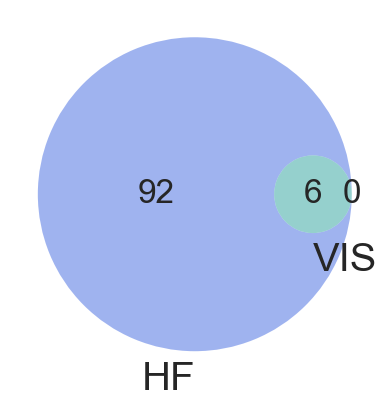

In [18]:
v = venn2(subsets = (np.sum(ls_n1) - np.sum(ls_n3) , np.sum(ls_n2) - np.sum(ls_n3), np.sum(ls_n3)), 
          set_labels = (cond1, cond2), 
          set_colors = ('royalblue', 'green'), alpha = 0.5)

# plt.savefig(f'venn2_{cond1}_{cond2}.pdf', transparent=True)

In [ ]:
arr = np.array([ls_n1, ls_n2, ls_n3])
df = pd.DataFrame(arr)
df.to_excel('arrayd.xlsx', index=False, header=False)

### Plot tuning curves across cond

In [12]:
def categorize_numbers(a, b, c):
    # Convert to sets for efficient operations
    set_a, set_b, set_c = set(a), set(b), set(c)
    
    # Find numbers in each combination
    all_three = set_a & set_b & set_c
    
    only_a = set_a - set_b - set_c
    only_b = set_b - set_a - set_c
    only_c = set_c - set_a - set_b
    
    a_and_b = (set_a & set_b) - set_c
    b_and_c = (set_b & set_c) - set_a
    a_and_c = (set_a & set_c) - set_b
    
    # Also get all unique numbers for reference
    all_numbers = set_a | set_b | set_c
    
    return {
        'all': sorted(all_three),
        'l1_only': sorted(only_a),
        'd1_only': sorted(only_b),
        'vr_only': sorted(only_c),
        'a1_vr': sorted(a_and_b),
        'd1-vr': sorted(b_and_c),
        'l1_d1': sorted(a_and_c),
        # 'all_unique': sorted(all_numbers)  # Optional
    }

# Example usage
a = [1, 2, 3, 4, 5]
b = [4, 5, 6, 7, 8]
c = [5, 8, 9, 10, 11]

result = categorize_numbers(a, b, c)

# Print results
for category, numbers in result.items():
    print(f"{category}: {numbers}")

all: [5]
l1_only: [1, 2, 3]
d1_only: [6, 7]
vr_only: [9, 10, 11]
a1_vr: [4]
d1-vr: [8]
l1_d1: []


#### Plot RL, RD, VR-YawFree

In [ ]:
data = df_tun_proc[ (df_tun_proc.hdc == 1)
                   & ((df_tun_proc.cond == 'TS7-HF')  | (df_tun_proc.cond == 'L1') | (df_tun_proc.cond == 'D1'))
                   # & (df_tun_proc.rec_session == 'JA180_20220809')
                     ]

cond_ls = ['L1', 'D1', 'TS7-HF']
vr_rec_sess = data[data['cond'] == 'TS7-HF'].rec_session.unique()
# data = df_tun_loc
angles = np.arange(0, 360, 20)
d_hdc_across_cond_rev = {}
ang_rad = np.deg2rad(angles)
ang_rad = np.append(ang_rad, ang_rad[0])
current_palette = ['orange','gray', 'royalblue']
ls_df = []

for rec in vr_rec_sess[:]:

    if 'JA178_20220819' not in rec:
        continue
    print(rec)
    tmp = data[data.rec_session == rec]
    if tmp.cond.unique().size < 3:
        continue
    rec_hdc = tmp[tmp.dir == 0].groupby([ 'cond'])['rec_unit'].apply(list).reset_index()
    cond_hdc_a = rec_hdc[rec_hdc.cond == cond_ls[0]]['rec_unit'].values[0]
    cond_hdc_b = rec_hdc[rec_hdc.cond == cond_ls[1]]['rec_unit'].values[0]
    cond_hdc_c = rec_hdc[rec_hdc.cond == cond_ls[2]]['rec_unit'].values[0]
    d_hdc_across_cond = {}
    d_hdc_across_cond = categorize_numbers(cond_hdc_a, cond_hdc_b, cond_hdc_c)
    for name, numbers in d_hdc_across_cond.items():
        for num in numbers:
            if num not in result:  # Only set if not already present
                d_hdc_across_cond_rev[num] = name
            
#     print(rec)
    
    for unit in d_hdc_across_cond['all'][:]:
        print(unit)
        ax = plt.subplot(111, projection = 'polar')
#         ax.yaxis.grid(linewidth=0)
#         ax.xaxis.grid(linewidth=6)
        ax.set_yticklabels([])
        # ax.set_xticklabels([])
        ax.grid(False)
    #         ax.set_theta_zero_location("N")
    #         ax.set_theta_direction(-1)
        
        for idx, cn in enumerate(cond_ls):
            max_fr_cond = math.ceil(tmp[(tmp.rec_unit == unit)]['hz'].max()) + 2
            this_unit = tmp[(tmp.rec_unit == unit) & (tmp.cond == cn)]
            this_fr, this_r = this_unit.hz.values, np.round(this_unit.r.min(), 2)
            this_fr = np.append(this_fr, this_fr[0])
            max_fr = round(this_fr.max())

            # angles were reflected in arena code, so use[::-1] for arena
            if '1' in cn:
                this_ang = ang_rad[::-1]
            else:
                this_ang = ang_rad
            pref_dir = this_ang[np.argmax(this_fr)]
            pref_dir_circ = round(circ_preferred_direction(this_fr[:], this_ang[:]))
            
            ax.set_rlim(0, max_fr_cond)
            ax.plot(this_ang, this_fr, label = f'{this_r}, {max_fr} Hz' , c = current_palette[idx], zorder=1)
            # ax.plot(pref_dir_circ, max_fr, c = current_palette[idx])
            ax.plot(np.deg2rad(pref_dir_circ), max_fr_cond*0.95, 'o', markersize = 10, c = current_palette[idx], zorder=10)
            

            # print(pref_dir_circ, np.rad2deg(pref_dir))
            # tmp_df = pd.DataFrame({'rec_session':rec, 'rec_unit': unit, 'cond': cn, 'pref_dir': pref_dir, 'pref_dir_circ':pref_dir_circ,'tun_peak_fr': max_fr, 'r': this_r }, index = [0])
            # ls_df.append(tmp_df)
            
            ax.set_title(f'{unit}')
            ax.legend(loc='best', bbox_to_anchor=(1.5, 0.5, 0.5, 0.5))
        plt.show()
        # break
#         fr_resam, results_half = hd_tuning_width(fr2)
#         plt.plot(fr_resam)
#         plt.hlines(*results_half[1:])
        ax.set_xticks(np.pi/180. * np.linspace(180,  -180, 8, endpoint=False))
        ax.set_thetalim(-np.pi, np.pi)
        
    
        # time.sleep(0.1)
        # filepath = save_dir / f'polar_HD_tuning_{rec}_{unit}.pdf'
        # plt.savefig(filepath, transparent = True)
    
        # plt.savefig(f'{rec}_{unit}_L_TS6-HF_run.pdf' , transparent=True)
        plt.clf()
    # break
# df_pref_remap = pd.concat(ls_df)
# df_pref_remap.head()

In [ ]:
# Fig 1 tuning curves
uoi = ['JA179_20220804_114.0', 'JA179_20220804_34.0', 'JA179_20220804_35.0']
tmp[(tmp.rec_unit.isin(uoi))][['rec_unit', 'dir',  'hz', 'cond']].pivot(index = ['cond', 'rec_unit'] , columns = 'dir', values = 'hz').to_excel(filepath, index=True)

In [ ]:
# Figure S3
uoi = ['JA178_20220819_115.0', 'JA178_20220819_12.0', 'JA178_20220819_5.0',     'JA178_20220819_20.0', 'JA178_20220819_80.0', 'JA178_20220819_10.0' ]
tmp[(tmp.rec_unit.isin(uoi))][['rec_unit', 'dir',  'hz', 'cond']].pivot(index = ['cond', 'rec_unit'] , columns = 'dir', values = 'hz').to_excel(filepath, index=True)

#### Plot VR YawFree vs Fix

In [ ]:
this_unit.shape

In [ ]:
data = df_tun_proc[ (df_tun_proc.hdc > -1)
                   & (df_tun_proc.rec_id.isin(vis_rec_id))
                     ]

cond_ls = ['TS7-HF', 'TS7-VIS', 'TS6-VIS']

angles = np.arange(0, 360, 20)
d_hdc_across_cond_rev = {}
ang_rad = np.deg2rad(angles)
ang_rad = np.append(ang_rad, ang_rad[0])
current_palette = ['royalblue', 'magenta']
ls_df = []

for rec in data.rec_session.unique()[:]:

    # if 'JA179_20220804' not in rec:
    #     continue
    print(rec)
    tmp = data[data.rec_session == rec]
    cond_ls = tmp.cond.unique()
    session_hdc = tmp[tmp.hdc == 1].rec_unit.unique()
    
    for unit in session_hdc[:]:
        print(unit)
        ax = plt.subplot(111, projection = 'polar')
#         ax.yaxis.grid(linewidth=0)
#         ax.xaxis.grid(linewidth=6)
        ax.set_yticklabels([])
        # ax.set_xticklabels([])
        ax.grid(False)
    #         ax.set_theta_zero_location("N")
    #         ax.set_theta_direction(-1)
        
        for idx, cn in enumerate(cond_ls):
            this_unit = tmp[(tmp.rec_unit == unit) & (tmp.cond == cn)]
            # print(this_unit.shape)
            if this_unit.shape[0] < 10:
                continue
            max_fr_cond = math.ceil(tmp[(tmp.rec_unit == unit)]['hz'].max()) + 2
            this_fr, this_r = this_unit.hz.values, np.round(this_unit.r.min(), 2)
    #         angles_arena = tmp[(tmp.cids == unit) & (tmp.head_fixation == 'HF')].dir_adj
            this_fr = np.append(this_fr, this_fr[0])
            max_fr = round(this_fr.max())

            # angles were reflected in arena code, so use[::-1] for arena
            if '1' in cn:
                this_ang = ang_rad[::-1]
            else:
                this_ang = ang_rad
            pref_dir = this_ang[np.argmax(this_fr)]
            pref_dir_circ = round(circ_preferred_direction(this_fr[:], this_ang[:]))
            
            ax.set_rlim(0, max_fr_cond)
            ax.plot(this_ang, this_fr, label = f'{this_r}, {max_fr} Hz' , c = current_palette[idx], zorder=1)
            # ax.plot(pref_dir_circ, max_fr, c = current_palette[idx])
            ax.plot(np.deg2rad(pref_dir_circ), max_fr_cond*0.95, 'o', markersize = 10, c = current_palette[idx], zorder=10)
            

            # print(pref_dir_circ, np.rad2deg(pref_dir))
            # tmp_df = pd.DataFrame({'rec_session':rec, 'rec_unit': unit, 'cond': cn, 'pref_dir': pref_dir, 'pref_dir_circ':pref_dir_circ,'tun_peak_fr': max_fr, 'r': this_r }, index = [0])
            # ls_df.append(tmp_df)
            
            # ax.set_title(f'{unit}')
            ax.legend(loc='best', bbox_to_anchor=(1.5, 0.5, 0.5, 0.5))
        plt.show()
        # break
#         fr_resam, results_half = hd_tuning_width(fr2)
#         plt.plot(fr_resam)
#         plt.hlines(*results_half[1:])
        ax.set_xticks(np.pi/180. * np.linspace(180,  -180, 8, endpoint=False))
        ax.set_thetalim(-np.pi, np.pi)
        
    
        # time.sleep(0.1)
        # filepath = save_dir / f'polar_HD_tuning_{rec}_{unit}.pdf'
        # plt.savefig(filepath, transparent = True)
    
        # plt.savefig(f'{rec}_{unit}_L_TS6-HF_run.pdf' , transparent=True)
        plt.clf()
    # break
# df_pref_remap = pd.concat(ls_df)
# df_pref_remap.head()

In [ ]:
save_dir = Path(r"C:\Users\01\Documents")
filepath = save_dir / f'out.xlsx'

uoi = ['JA178_20220909_131.0', 'JA178_20220909_125.0', 'JA178_20220909_113.0']
data[(data.rec_unit.isin(uoi))][['rec_unit', 'dir',  'hz', 'cond']].pivot(index = ['cond', 'rec_unit'] , columns = 'dir', values = 'hz').to_excel(filepath, index=True)

### Remapping of HDC

In [20]:
def compute_remap_hdc_prop(off_LV): 
    threshold = 30
    abs_off_LV = abs(off_LV)
    mean_offset = np.mean(abs_off_LV)
    remap_hdc_n = np.where((abs_off_LV > mean_offset + threshold) | (abs_off_LV < mean_offset - threshold))[0].size
    remap_prop = remap_hdc_n/abs_off_LV.size
    return round(remap_prop,2 )

def plot_pref_dir(pref_light, pref_dark, pref_vr):
    f, ax_A = plt.subplots(figsize = (4, 4))
    n_cells = len(pref_light)
    sort_idx = np.argsort(pref_light)
    x = np.arange(n_cells)
    ax_A.plot(x, pref_light[sort_idx], "o", color=COLORS["light"], ms=5,
              label="Light", alpha=0.85, zorder=3)
    ax_A.plot(x, pref_dark[sort_idx],  "s", color=COLORS["dark"],  ms=5,
              label="Dark",  alpha=0.85, zorder=2)
    ax_A.plot(x, pref_vr[sort_idx],    "^", color=COLORS["vr"],    ms=5,
              label="VR",    alpha=0.85, zorder=1)
    ax_A.set_xlabel("Cell (sorted by Light pref. dir.)", fontsize=10)
    ax_A.set_ylabel("Preferred direction (°)", fontsize=10)
    ax_A.set_yticks([0, 90, 180, 270, 360])
    ax_A.set_ylim(-5, 365)
    ax_A.legend(fontsize=8, loc="upper left")
    ax_A.set_title("A  Per-cell preferred directions", fontsize=10, loc="left")
    return

In [ ]:
df_pref_remap.head()

In [ ]:
COLORS = {"light": "#E87722", "dark": "#555555", "vr": "#2C7BB6"}
ls = [] 

for rec in df_pref_remap.rec_session.unique():
    print(rec)

    # if 'JA178_20220819' not in rec:
    #     continue
            
    this_rec = df_pref_remap[df_pref_remap.rec_session == rec]
    pref_light = (this_rec[this_rec.cond == 'L1'].pref_dir_circ.values)
    pref_dark = (this_rec[this_rec.cond == 'D1'].pref_dir_circ.values)
    pref_vr = (this_rec[this_rec.cond == 'TS7-HF'].pref_dir_circ.values)
    if pref_vr.size < 10:
        continue
    
    mean_LD, std_LD, off_LD = ensemble_offset(pref_light, pref_dark)
    mean_LV, std_LV, off_LV = ensemble_offset(pref_light, pref_vr)
    mean_DV, std_DV, off_DV = ensemble_offset(pref_dark, pref_vr)
    print (mean_LV, std_LV, off_LV)
    r_LD, r_LV = pairwise_preservation_test(pref_light, pref_dark, pref_vr)
    remap_prop_LD = compute_remap_hdc_prop(off_LD)
    remap_prop_LV = compute_remap_hdc_prop(off_LV)

    tmp_df = pd.DataFrame({'rec_session': rec, 'r_LD':r_LD, 'r_LV':r_LV, 'remap_prop_LD':remap_prop_LD, 
                           'remap_prop_LV': remap_prop_LV}, index = [0])
    ls.append(tmp_df)
    
    pw_L = pairwise_angular_differences(pref_light)
    pw_D = pairwise_angular_differences(pref_dark)
    pw_V = pairwise_angular_differences(pref_vr)
    
    plot_pref_dir(pref_light, pref_dark, pref_vr)
    print(pearsonr(pw_L, pw_V))
    # filepath = save_dir / f'scatter_prefdir_{rec}.pdf'
    # plt.savefig(filepath, transparent = True)
    
    plt.show()
    break
    
# df_remap_r = pd.concat(ls)
# df_remap_r_long = df_remap_r.melt(id_vars = ['rec_session'])
# df_remap_r_long.head()

In [ ]:
# this_rec['cond'] = this_rec['cond'].replace({'L1': 'RL', 'D1': 'RD', 'TS7-HF': 'VR-YawFree'})
# this_rec.to_excel(filepath, index = True)

In [ ]:
this_rec.head()

#### Proportion of remapped HDC

In [ ]:
f, ax = plt.subplots(figsize = (5, 5))
y = 'value'
sns.boxplot(data=df_remap_r[['remap_prop_LD', 'remap_prop_LV']])
sns.stripplot(data=df_remap_r[['remap_prop_LD', 'remap_prop_LV']], s = 10, color = 'k')
# plt.savefig(f'box_remap_ratio_LD-LV.pdf' , transparent=True)

In [ ]:
df_remap_r_long.groupby('variable').describe()

In [ ]:
a1 = df_remap_r_long[(df_remap_r_long.variable == 'remap_prop_LD') ][y].values
a2 = df_remap_r_long[(df_remap_r_long.variable == 'remap_prop_LV') ][y].values

stat1, pval1 = stats.mannwhitneyu(a1, a2)
print(f'remap % LD vs LVR {stat1} {pval1}')

In [ ]:
df_remap_r_long.to_excel(filepath, index = True)

In [ ]:
unity_line = [-5, 200]
plt.plot(unity_line, unity_line, 'k')
sns.scatterplot(x = pw_L, y = pw_D, color='gray')
print(pearsonr(pw_L, pw_D))

# plt.savefig(f'scatter_pw_L-pw_D_ex2.pdf' , transparent=True)

In [ ]:
unity_line = [-5, 200]
plt.plot(unity_line, unity_line, 'k')
sns.scatterplot(x = pw_L, y = pw_V, color='royalblue')
print(pearsonr(pw_L, pw_V))

# plt.savefig(f'scatter_pw_L-pw_V_ex2.pdf' , transparent=True)

In [ ]:
# pd.DataFrame({'pw_L': pw_L, 'pw_D': pw_D, 'pw_V': pw_V}).to_excel(filepath, index = True)

In [ ]:
df_remap_r_long.head()

In [ ]:
y = 'value'
_inp = df_remap_r_long[df_remap_r_long['variable'].str.contains('r_')]
g = sns.catplot(
    data=_inp, 
    x="variable", 
    y="value", 
    kind="box", 
    height=5,     # Height is 5 inches
    aspect=1    # Width will be 5 * 1.5 = 7.5 inches
)

g.map_dataframe(
    sns.swarmplot,
    x="variable", 
    y="value", 
    color = 'k',
    s = 7
)

# plt.savefig(f'box_pw_LD-LV.pdf' , transparent=True)

In [ ]:
_inp.groupby('variable').describe()

In [ ]:
a1 = _inp[(_inp.variable == 'r_LD') ][y].values
a2 = _inp[(_inp.variable == 'r_LV') ][y].values

stat1, pval1 = stats.mannwhitneyu(a1, a2)
print(f'r LD vs LVR {stat1} {pval1}')

### Single cell FR and r of HDC

In [ ]:
y = 'hz'
coi = ['L1', 'D1', 'TS7-HF']
# pal = ('royalblue', 'magenta')
# pal = ('darkgreen', 'lightgreen')
pal = ('orange', 'gray', 'royalblue')

vr_sess = df_tun_proc[df_tun_proc.cond == 'TS7-HF'].rec_session.unique()
_inp_plot = df_tun_proc[ ((df_tun_proc.cond.isin(coi))) 
    & (df_tun_proc.hdc == 1) & (df_tun_proc.rec_session.isin(vr_sess))
            # & (data.rec_unit.isin(rec_units))
            ].groupby(['mouse_id', 'rec_session','rec_id', 'cids', 'cond'])[y].max().reset_index()


sns.kdeplot(x = y, data = _inp_plot, hue = 'cond',  fill=False, hue_order= coi,
            cumulative=False, common_grid=True,
           common_norm = False, legend = True, 
#             cut = 0,
            palette = pal)


# plt.xlim(0, 1)
# filepath = save_dir / f'kde_{y}_{coi}_{cond2}.pdf'
# plt.savefig(filepath, transparent = True)

In [ ]:
_inp_plot.groupby(['cond', ])[y].describe()

In [ ]:
a1 = _inp_plot[_inp_plot.cond == coi[0]][y].values
b1 = _inp_plot[_inp_plot.cond == coi[1]][y].values
c1 = _inp_plot[_inp_plot.cond == coi[2]][y].values
print(f'test for {y}')
# print(f'# of implntations {_inp_plot.implant.unique().size}')

print(f'{coi[0]} vs {coi[1]}', stats.mannwhitneyu(a1, b1))
print(f'{coi[0]} vs {coi[2]}', stats.mannwhitneyu(a1, c1))

In [ ]:
_inp_plot['cond'] = _inp_plot['cond'].replace({'L1': 'RL', 'D1': 'RD', 'TS7-HF': 'VR-YawFree'})
_inp_plot.to_excel(filepath, index = True)

#### VR-YawFree vs Fix

In [ ]:
_inp_plot.head_fixation.unique()

In [ ]:
y = 'r'

coi = ['HF', 'VIS']
pal = ('royalblue', 'magenta')

rec_units = df_tun_proc[ (df_tun_proc.hdc == 1)
                   & (df_tun_proc.rec_id.isin(vis_rec_id))
                     ].rec_unit.unique()

_inp_plot = df_tun_proc[  (df_tun_proc.rec_id.isin(vis_rec_id))
            & (df_tun_proc.rec_unit.isin(rec_units))
            ].groupby(['mouse_id', 'rec_session','rec_id', 'cids', 'head_fixation'])[y].max().reset_index()

sns.kdeplot(x = y, data = _inp_plot, hue = 'head_fixation',  fill=False, hue_order= coi,
            cumulative=False, common_grid=True,
           common_norm = False, legend = True, 
#             cut = 0,
            palette = pal)


# plt.xlim(0, 1)
# filepath = save_dir / f'kde_{y}_{coi}_{cond2}.pdf'
# plt.savefig(filepath, transparent = True)

In [ ]:
_inp_plot.groupby(['head_fixation', ])[y].describe()

In [ ]:
a1 = _inp_plot[_inp_plot.head_fixation == coi[0]][y].values
b1 = _inp_plot[_inp_plot.head_fixation == coi[1]][y].values
print(f'test for {y}')
# print(f'# of implntations {_inp_plot.implant.unique().size}')

print(f'{coi[0]} vs {coi[1]}', stats.mannwhitneyu(a1, b1))

In [ ]:
_inp_plot.head()

In [ ]:
# _inp_plot['head_fixation'] = _inp_plot['head_fixation'].replace({'HF': 'VR-YawFree', 'VIS': 'VR-YawFix'})
# _inp_plot.to_excel(filepath, index = True)

# Stat vs Run

In [13]:
df_tun_run.head()

,hz,dir,cids,mouse_id,r,p_val,rec_id,dts,run,cuid,hem,cond,rec_session
0,27.476122,0.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818
1,19.187135,20.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818
2,4.421405,40.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818
3,5.623632,60.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818
4,7.933673,80.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818


In [22]:
_inp_plot.head()

NameError: name '_inp_plot' is not defined

<Axes: xlabel='cond', ylabel='hz'>

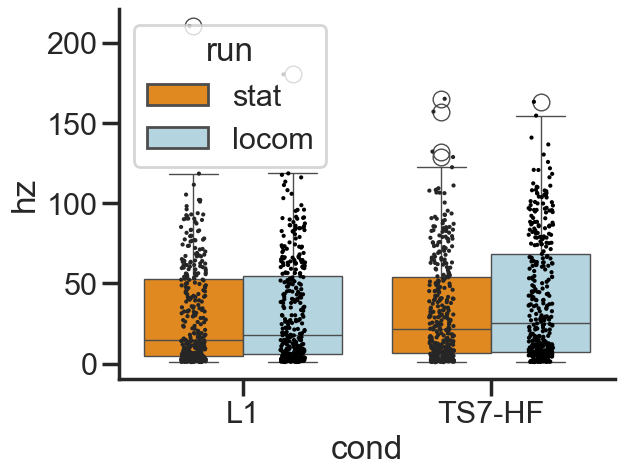

In [20]:
y = 'hz'
cond1 = 'stat'
cond2 = 'locom'
coi = ['L1', 'TS7-HF']

# sessions_in = df_betti[(df_betti.cond == 'TS6-HF') & (df_betti.stat_off_manifold > 0.5)].rec_session.unique()

pal = ('darkorange', 'lightblue', 'gold',  'darkblue',)
vr_sess = df_tun_proc[df_tun_proc.cond == 'TS7-HF'].rec_session.unique()

_inp_plot = df_tun_run[df_tun_run.cond.isin(coi)
            & (df_tun_run.rec_session.isin(vr_sess))].groupby([ 'cond', 'rec_id', 'run', 'cids'])[y].max().reset_index()
_inp_plot2 = _inp_plot.pivot(index = ['cond', 'rec_id', 'cids'], columns = 'run', values = y).dropna().reset_index()
_inp_plot3 = pd.melt(_inp_plot2, id_vars = ['cond', 'rec_id', 'cids'], value_vars = ['stat', 'locom'], value_name=y)

sns.boxplot(data=_inp_plot3, x ='cond', y = y, hue = 'run', palette = pal)
sns.stripplot(data=_inp_plot3, x ='cond', y = y, hue = 'run', size = 3,
              dodge = True, palette='dark:black', legend = None)

# plt.xlim(0, 1)
# fname = f'kde_TS6-HF_{y}_{cond1}_{cond2}.pdf'
# plt.savefig(f'boxplot_{coi}_{y}.pdf', transparent=True)

In [21]:
_inp_plot3.groupby(['cond', 'run'])[y].describe()

count       mean        std       min       25%        50%  \
cond   run                                                                 
L1     locom  354.0  31.789100  31.259930  1.051664  5.839209  18.081360   
       stat   354.0  30.180392  30.792262  1.028169  5.090538  14.753077   
TS7-HF locom  365.0  39.761123  37.363657  1.024806  7.579646  25.083582   
       stat   365.0  32.990929  32.317494  1.000000  6.666667  21.748571   

                    75%         max  
cond   run                           
L1     locom  54.362328  180.211982  
       stat   53.056982  210.250000  
TS7-HF locom  68.374429  163.106132  
       stat   53.835294  165.000000

In [25]:
a1 = _inp_plot3[(_inp_plot3.cond == coi[0]) & (_inp_plot3.run == 'stat')][y].values
a2 = _inp_plot3[(_inp_plot3.cond == coi[0]) & (_inp_plot3.run == 'locom')][y].values
b1 = _inp_plot3[(_inp_plot3.cond == coi[1]) & (_inp_plot3.run == 'stat')][y].values
b2 = _inp_plot3[(_inp_plot3.cond == coi[1]) & (_inp_plot3.run == 'locom')][y].values


print(f'test for {y}')
# print(f'# of implntations {_inp_plot.implant.unique().size}')
print(f'# of sessions {coi[0]} {_inp_plot3[_inp_plot3.cond == coi[0]].rec_id.unique().size}')
print(f'# of sessions {coi[1]} {_inp_plot3[_inp_plot3.cond == coi[1]].rec_id.unique().size}')


stat1, pval1 = stats.wilcoxon(a1, a2)
print(f'{coi[0]} stat vs run {stat1} {pval1}')
stat2, pval2 = stats.wilcoxon(b1, b2)
print(f'{coi[1]} stat vs run {stat2} {pval2}')
stat3, pval3 = stats.mannwhitneyu(a1, b1)
print(f'stat  {stat3} {pval3}')
stat4, pval4 = stats.mannwhitneyu(a2, b2)
print(f'run {stat4} {pval4}')
pvals = [pval1, pval2, pval3, pval4]  
print('Benjamini/Hochberg (non-negative)')
print(multipletests(pvals, alpha=0.05, method='fdr_bh'))


test for r
# of sessions L1 15
# of sessions TS7-HF 15
L1 stat vs run 21083.0 8.158066342449693e-08
TS7-HF stat vs run 12768.0 1.5008242022726538e-24
stat  65726.0 0.6873690790359113
run 46117.0 3.141253402558464e-11
Benjamini/Hochberg (non-negative)
(array([ True,  True, False,  True]), array([1.08774218e-07, 6.00329681e-24, 6.87369079e-01, 6.28250681e-11]), 0.012741455098566168, 0.0125)


<Axes: xlabel='hz', ylabel='Density'>

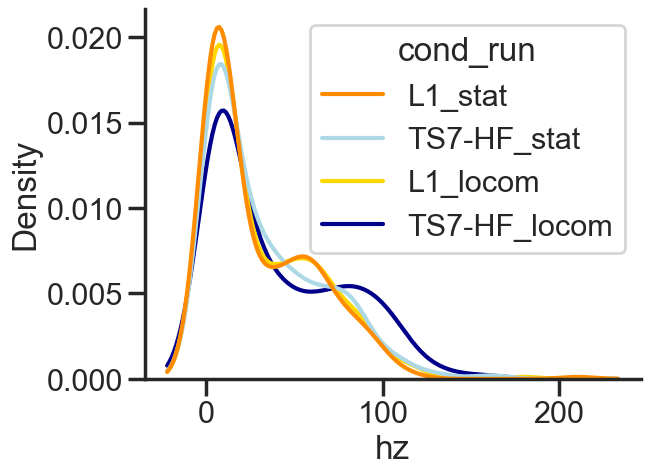

In [26]:
y = 'hz'
cond1 = 'stat'
cond2 = 'locom'

# sessions_in = df_betti[(df_betti.cond == 'TS6-HF') & (df_betti.stat_off_manifold > 0.5)].rec_session.unique()

pal = ('darkorange', 'lightblue', 'gold',  'darkblue',)

_inp_plot = df_tun_run[df_tun_run.cond.isin(coi)
            & (df_tun_run.rec_session.isin(vr_sess))].groupby([ 'cond', 'rec_id', 'run', 'cids'])[y].max().reset_index()
_inp_plot2 = _inp_plot.pivot(index = ['cond', 'rec_id', 'cids'], columns = 'run', values = y).dropna().reset_index()
_inp_plot3 = pd.melt(_inp_plot2, id_vars = ['cond', 'rec_id', 'cids'], value_vars = ['stat', 'locom'], value_name=y)
_inp_plot3['cond_run'] = _inp_plot3['cond'] + '_' + _inp_plot3['run']


sns.kdeplot(x = y, data = _inp_plot3, hue = 'cond_run',  fill=False, 
            cumulative=False, common_grid=True,
           common_norm = False, legend = True, 
#             cut = 0,
            palette = pal)


# plt.xlim(0, 1)
# fname = f'kde_TS6-HF_{y}_{cond1}_{cond2}.pdf'
# plt.savefig(f'kde_{coi}_{y}.pdf', transparent=True)

In [187]:
df_tun_run.head()

,hz,dir,cids,mouse_id,r,p_val,rec_id,dts,run,cuid,hem,cond,rec_session
0,27.476122,0.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818
1,19.187135,20.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818
2,4.421405,40.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818
3,5.623632,60.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818
4,7.933673,80.0,1.0,JA178,0.489239,0.0,20220818_JA178_lADN_red_H2_R_L1,20220818,stat,1-JA178-lADN-0818-L1na,lADN,L1,JA178_20220818


In [183]:
# _inp_plot3['cond'] = _inp_plot3['cond'].replace({'L1': 'RL', 'TS7-HF': 'VR-YawFree'})
# _inp_plot3.to_excel(filepath, index = True)

In [188]:
df_tun_run.cond.unique()

array(['L1', 'TS6-HF', 'TS7-HF'], dtype=object)

### Plot tuning curves

JA180_20220809
12.0


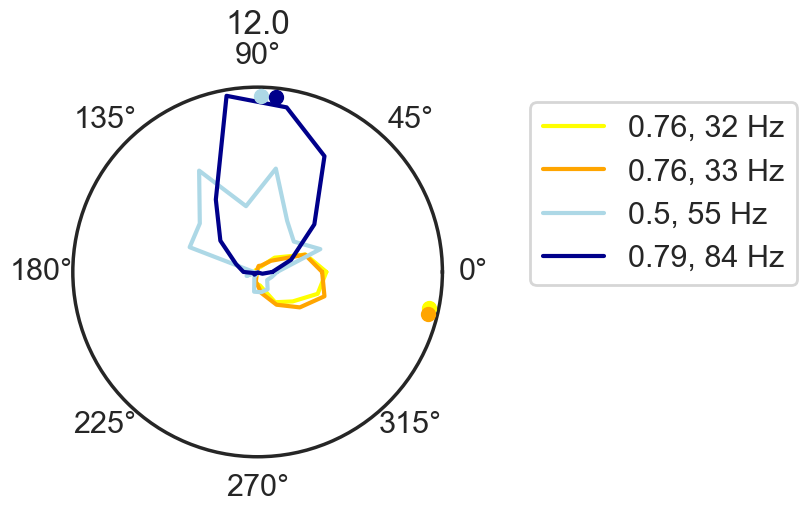

13.0


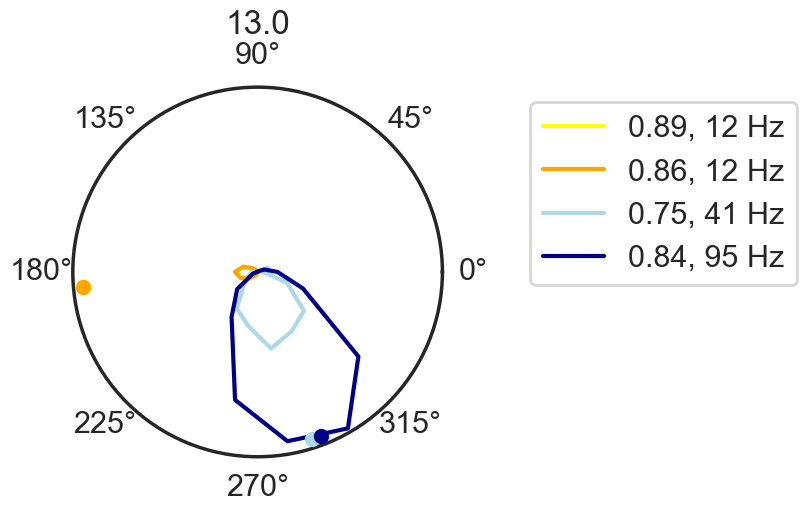

15.0


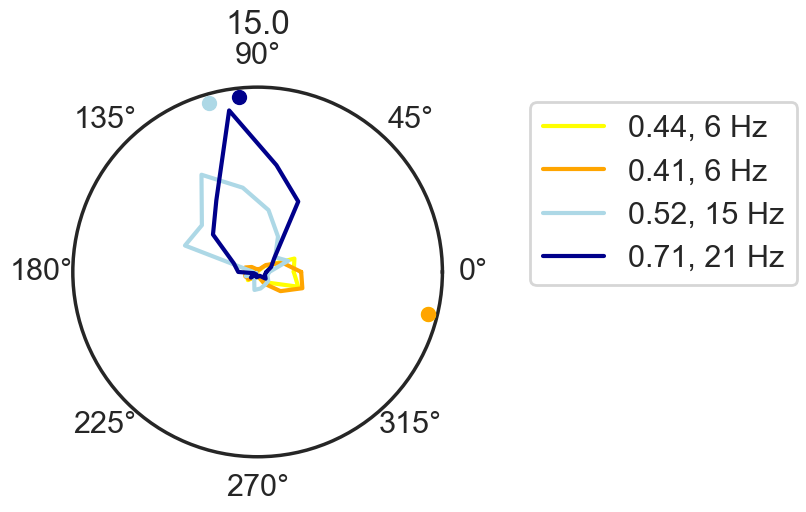

21.0


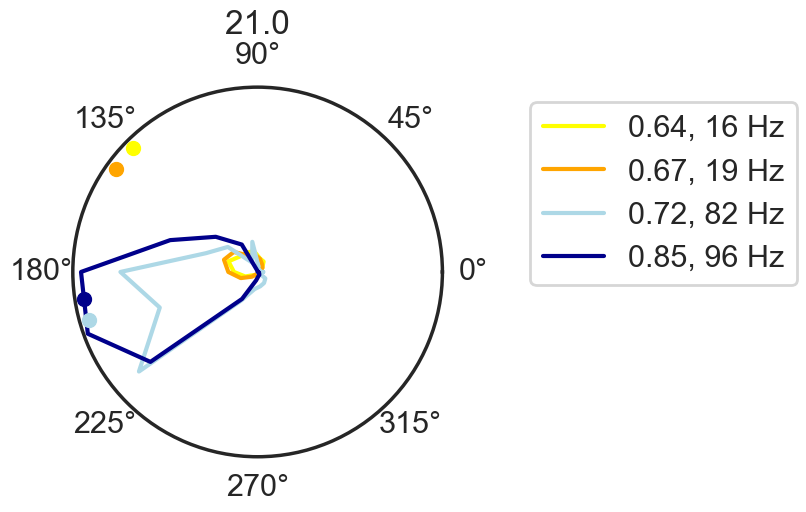

23.0


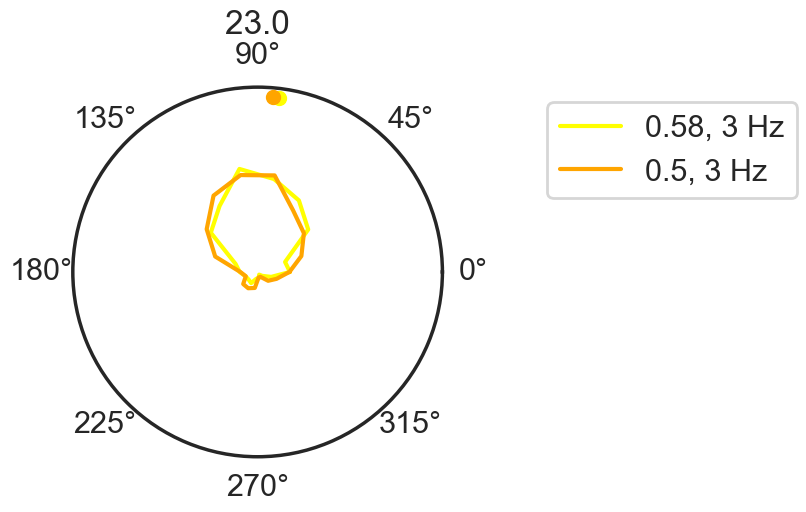

24.0


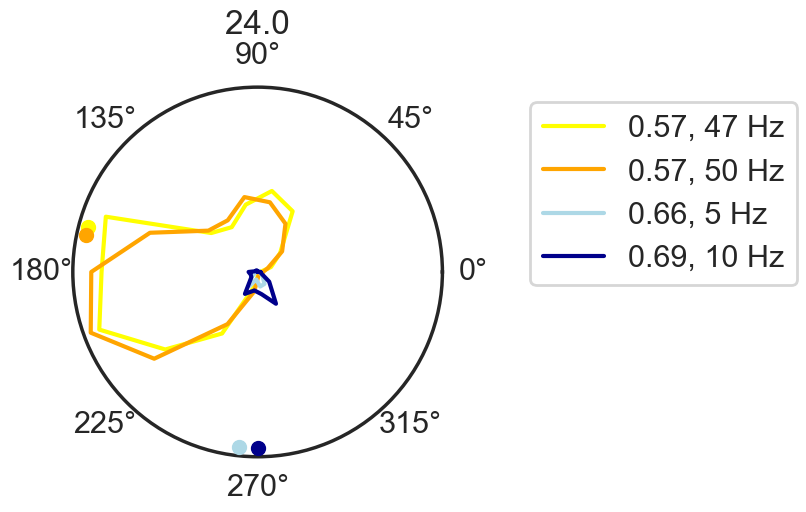

25.0


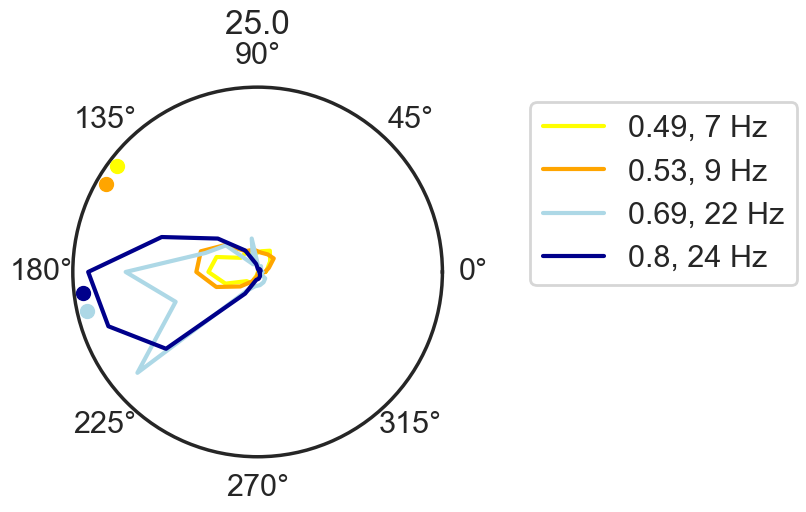

27.0


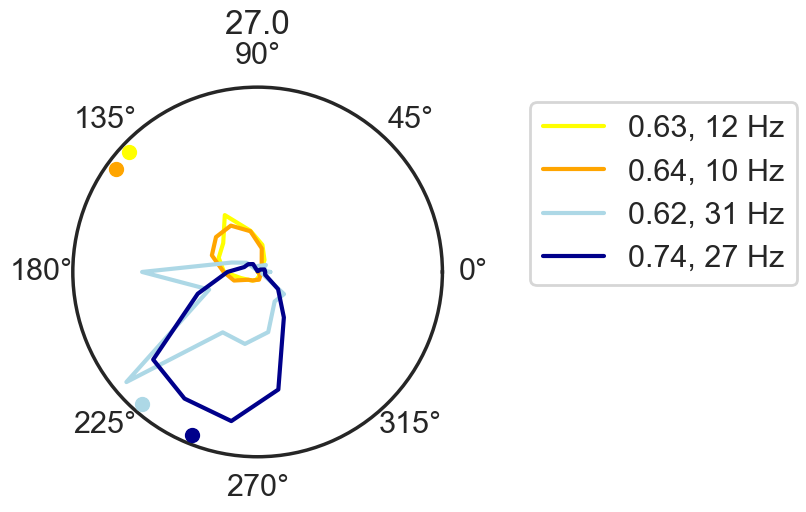

33.0


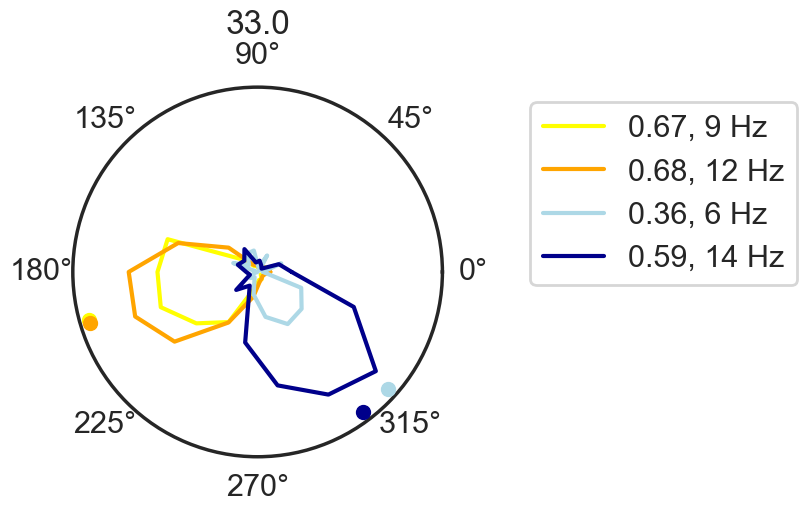

34.0


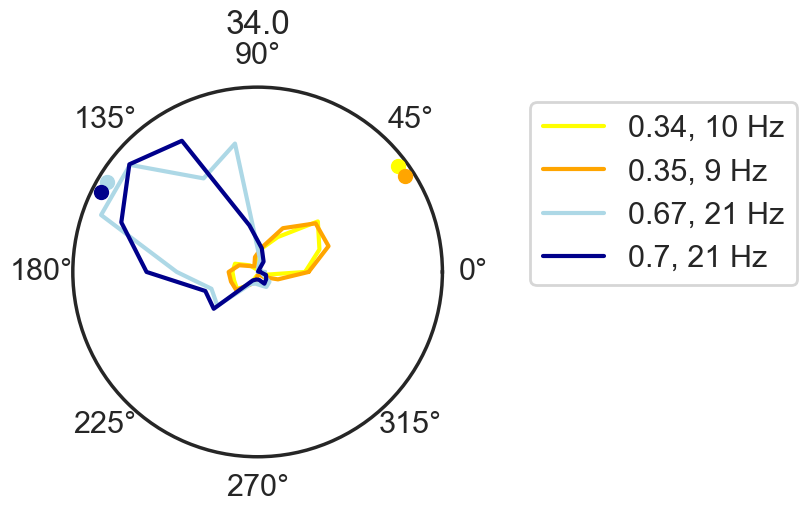

52.0


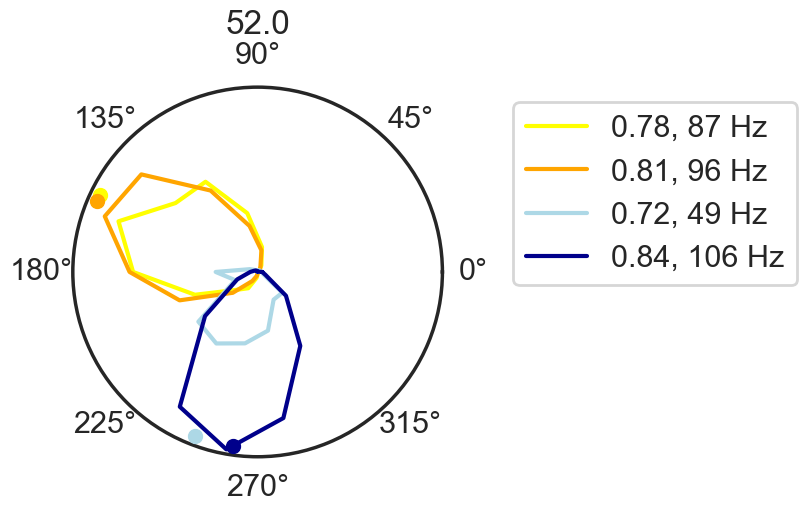

87.0


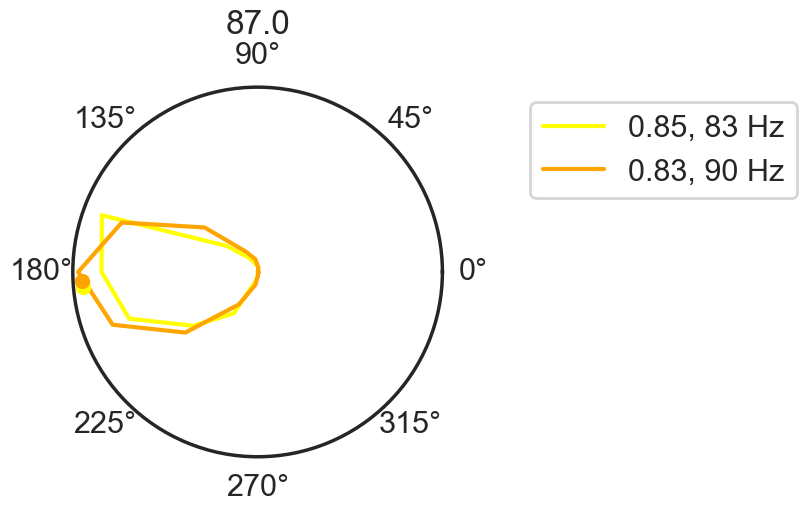

94.0


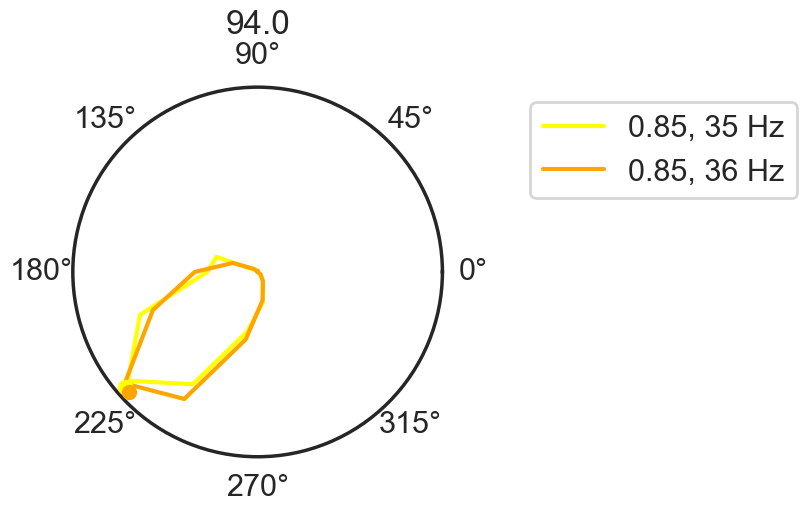

95.0


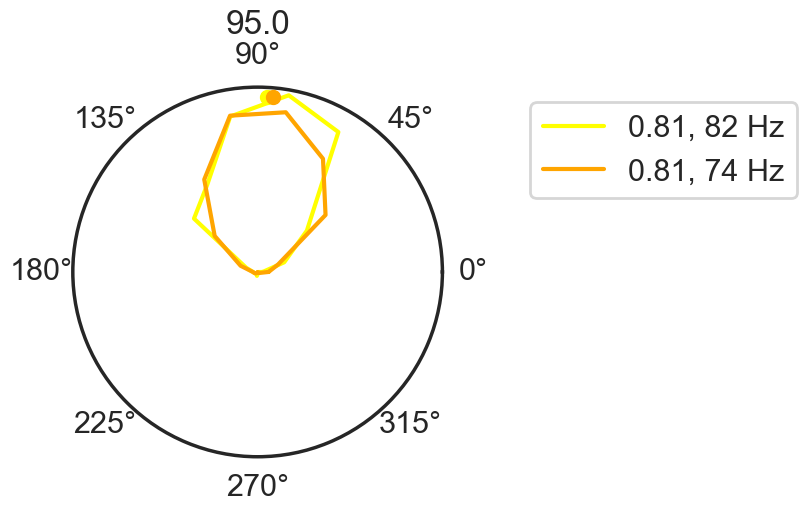

98.0


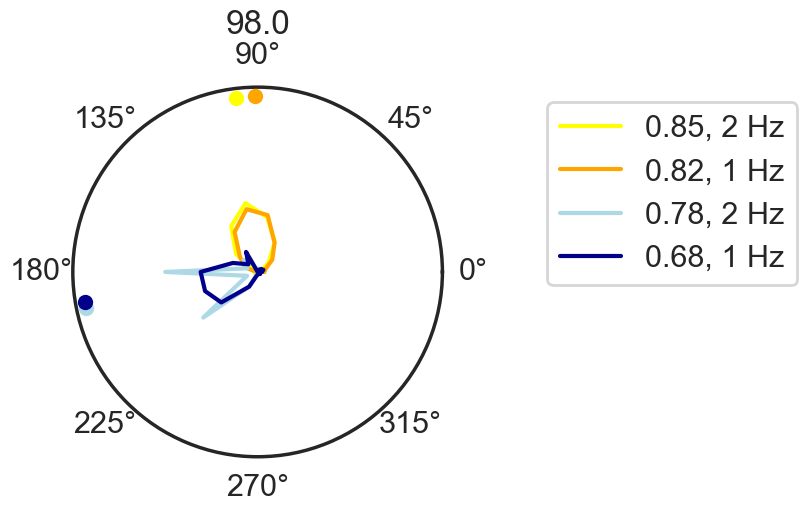

103.0


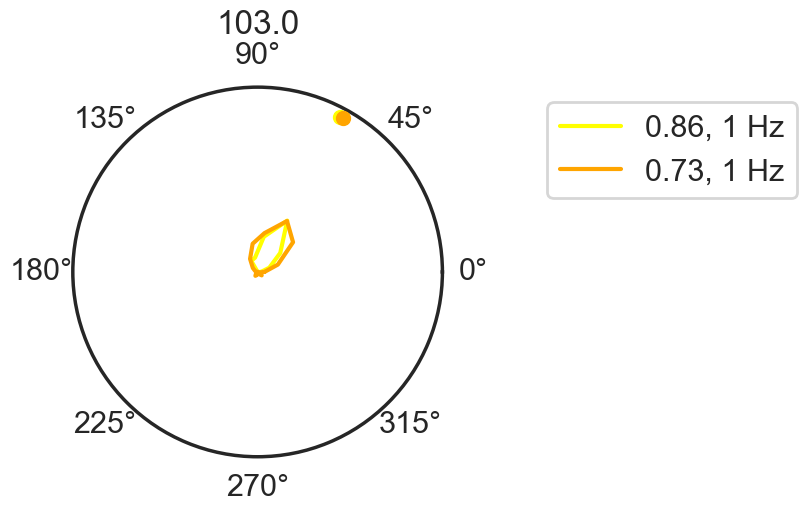

130.0


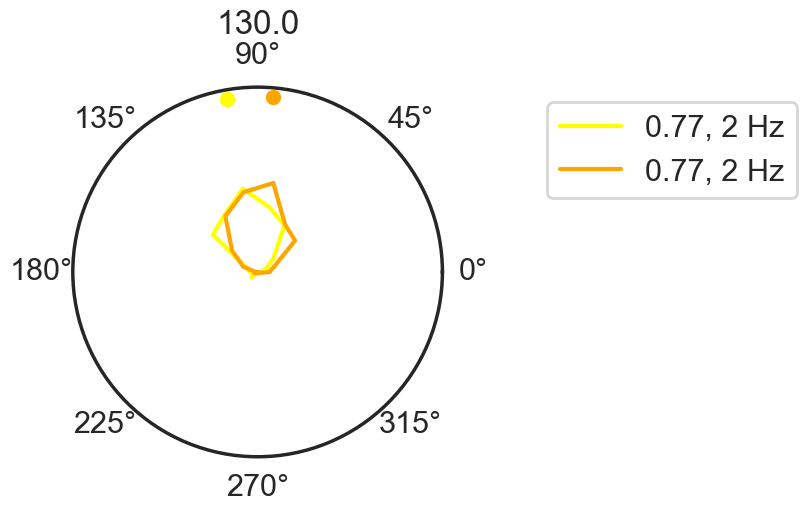

132.0


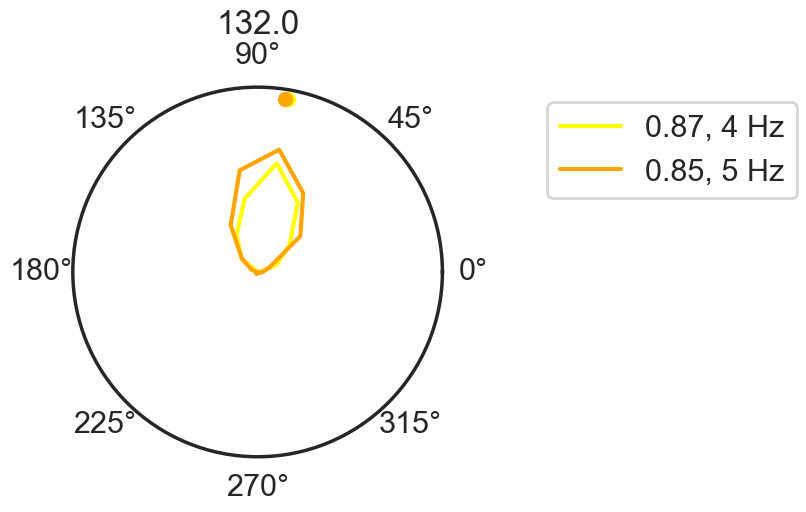

142.0


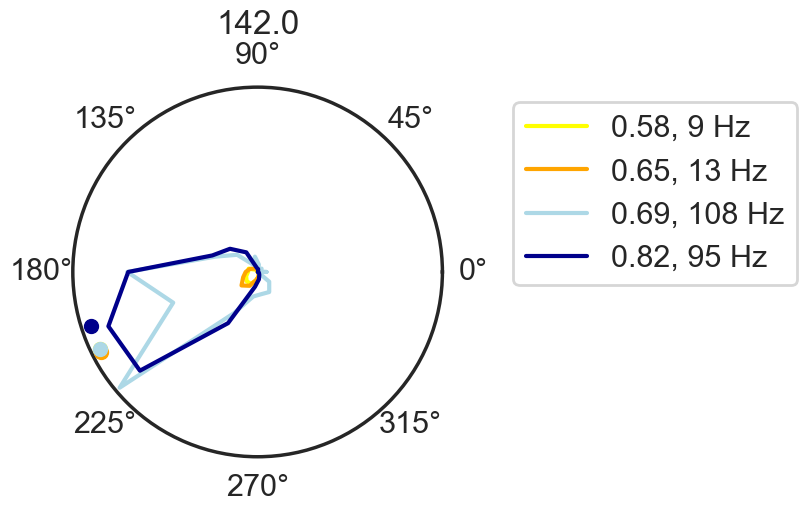

143.0


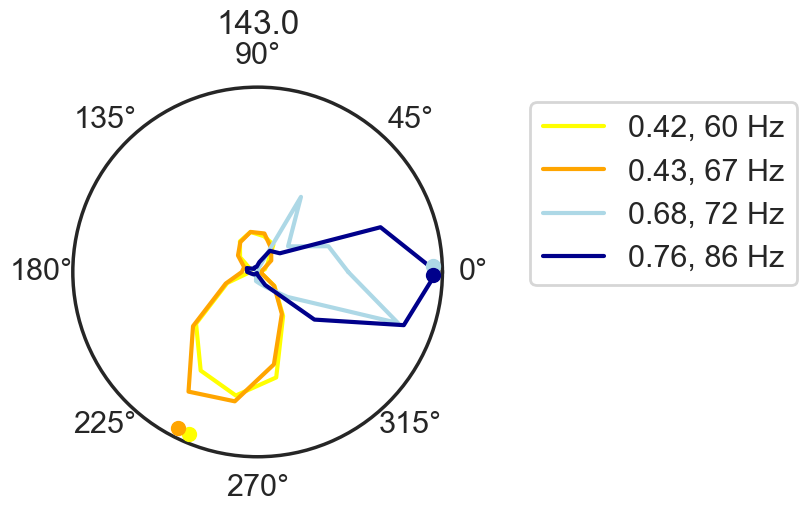

145.0


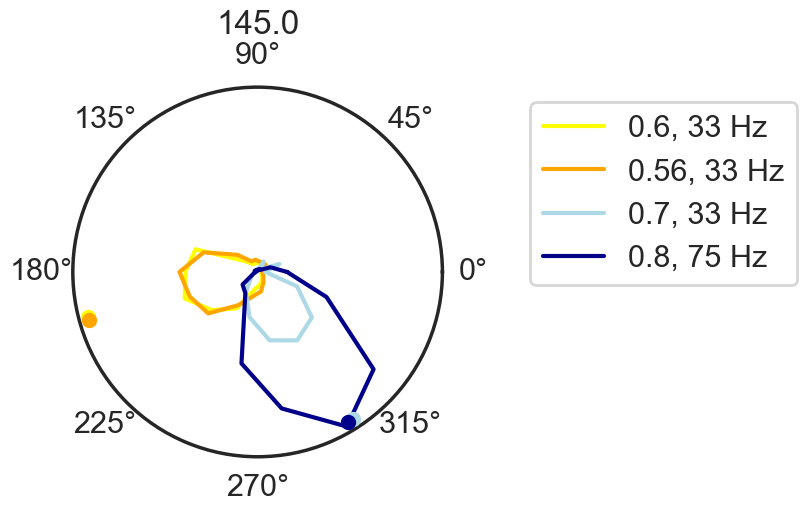

147.0


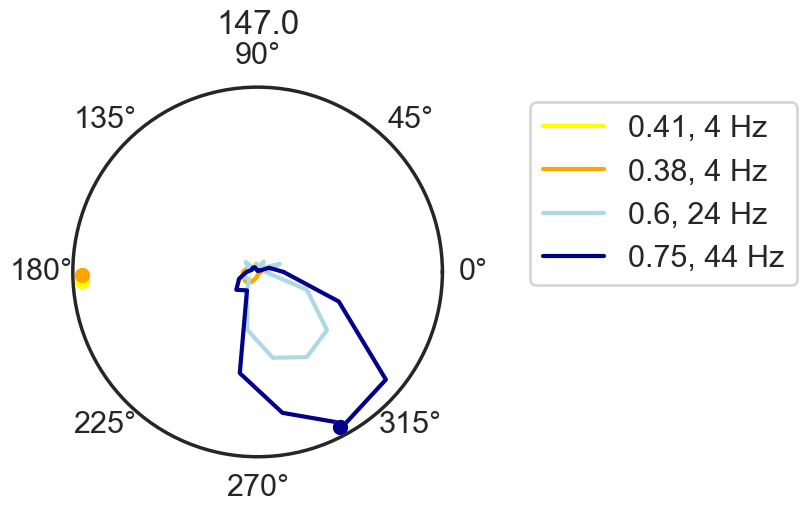

149.0


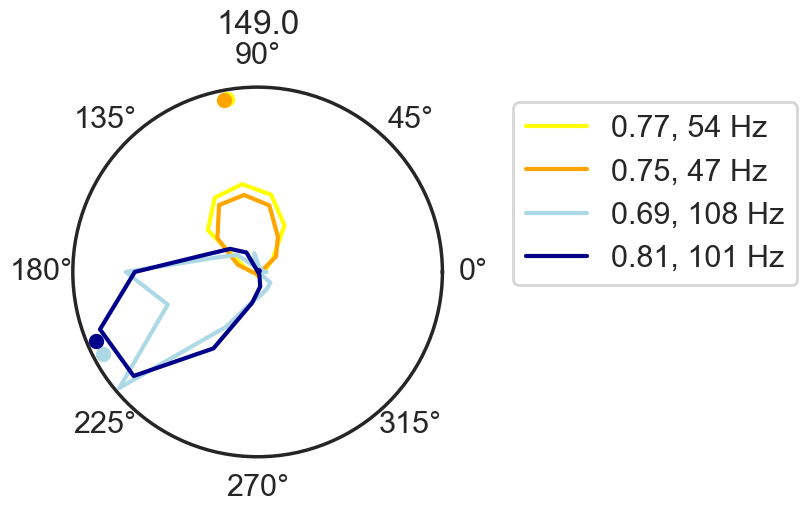

150.0


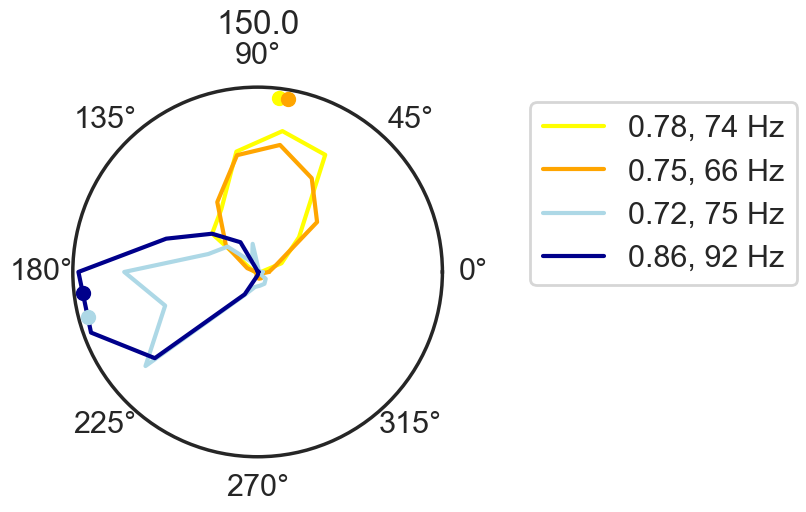

20.0


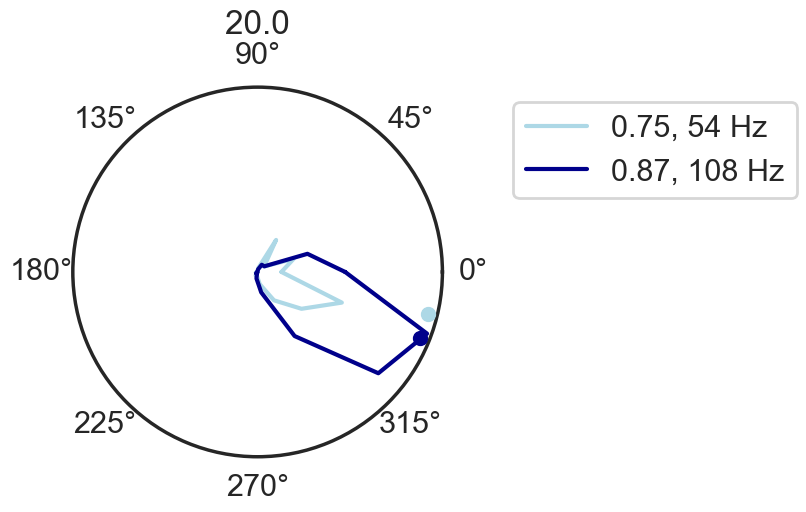

26.0


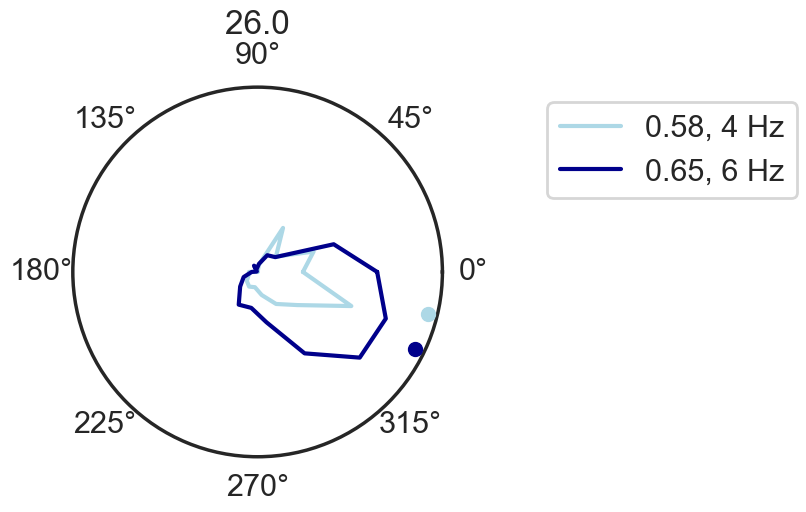

28.0


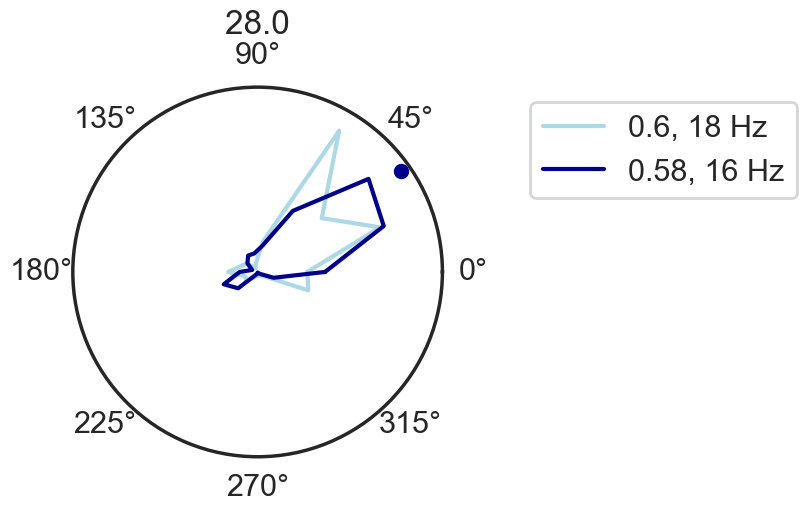

36.0


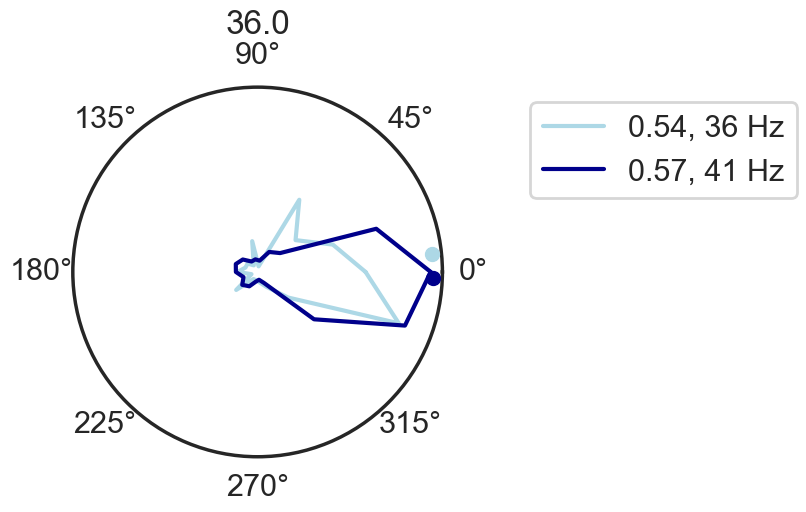

89.0


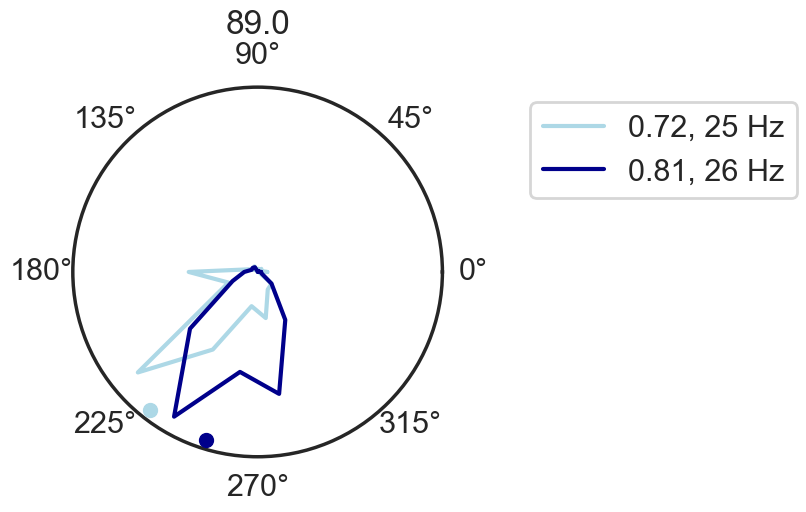

110.0


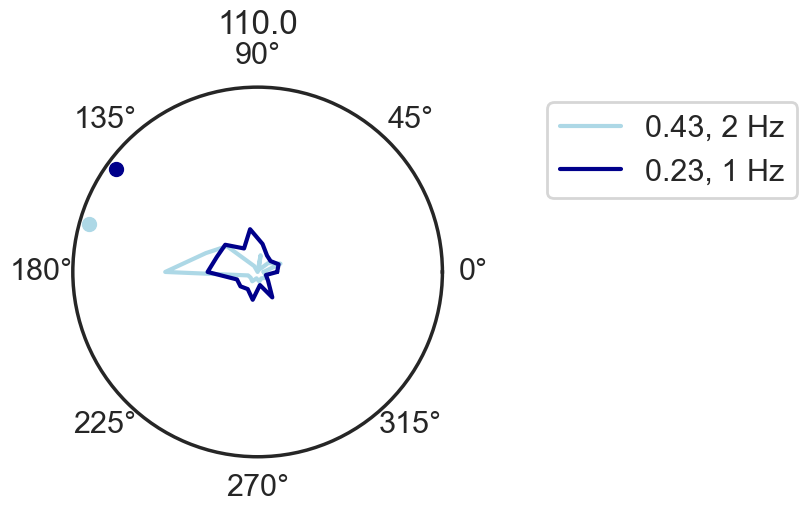

127.0


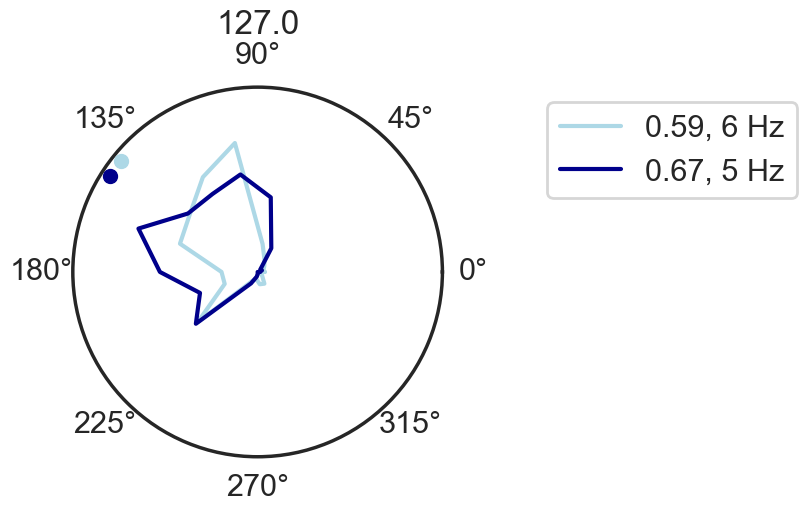

<Figure size 640x480 with 0 Axes>

In [22]:
data = df_tun_run[ ((df_tun_run.cond == 'TS7-HF')  | (df_tun_run.cond == 'L1') | (df_tun_run.cond == 'D1'))
                   # & (df_tun_proc.rec_session == 'JA180_20220809')
                     ]

cond_ls = ['L1', 'TS7-HF']
vr_rec_sess = data[data['cond'] == 'TS7-HF'].rec_session.unique()
# data = df_tun_loc
angles = np.arange(0, 360, 20)
d_hdc_across_cond_rev = {}
ang_rad = np.deg2rad(angles)
ang_rad = np.append(ang_rad, ang_rad[0])
current_palette = ['yellow', 'lightblue', 'orange', 'darkblue']
ls_df = []

for rec in vr_rec_sess[:]:

    if 'JA180_20220809' not in rec:
        continue
    print(rec)
    tmp = data[data.rec_session == rec]
    if tmp.cond.unique().size < 2:
        continue

#     print(rec)
    
    for unit in tmp.cids.unique()[:]:
        # if unit not in [52, 34, 143, 145]:
        #     continue
        print(unit)
        ax = plt.subplot(111, projection = 'polar')
#         ax.yaxis.grid(linewidth=0)
#         ax.xaxis.grid(linewidth=6)
        ax.set_yticklabels([])
        # ax.set_xticklabels([])
        ax.grid(False)
    #         ax.set_theta_zero_location("N")
    #         ax.set_theta_direction(-1)
        
        for idx, cn in enumerate(cond_ls):
            max_fr_cond = math.ceil(tmp[(tmp.cids == unit)]['hz'].max()) + 2
            
            for loc in ['stat', 'locom']:
                this_unit = tmp[(tmp.cids == unit) & (tmp.cond == cn) & (tmp.run == loc)]
                if this_unit.shape[0] < 2:
                    break
                this_fr, this_r = this_unit.hz.values, np.round(this_unit.r.min(), 2)
                this_fr = np.append(this_fr, this_fr[0])
                max_fr = round(this_fr.max())
    
                # angles were reflected in arena code, so use[::-1] for arena
                if '1' in cn:
                    this_ang = ang_rad[::-1]
                else:
                    this_ang = ang_rad
                pref_dir = this_ang[np.argmax(this_fr)]
                pref_dir_circ = round(circ_preferred_direction(this_fr[:], this_ang[:]))
                
                ax.set_rlim(0, max_fr_cond)
                ax.plot(this_ang, this_fr, label = f'{this_r}, {max_fr} Hz' , c = current_palette[idx], zorder=1)
                # ax.plot(pref_dir_circ, max_fr, c = current_palette[idx])
                ax.plot(np.deg2rad(pref_dir_circ), max_fr_cond*0.95, 'o', markersize = 10, c = current_palette[idx], zorder=10)
                
    
                # print(pref_dir_circ, np.rad2deg(pref_dir))
                # tmp_df = pd.DataFrame({'rec_session':rec, 'rec_unit': unit, 'cond': cn, 'pref_dir': pref_dir, 'pref_dir_circ':pref_dir_circ,'tun_peak_fr': max_fr, 'r': this_r }, index = [0])
                # ls_df.append(tmp_df)
                
                ax.set_title(f'{unit}')
                ax.legend(loc='best', bbox_to_anchor=(1.5, 0.5, 0.5, 0.5))
                idx = idx + 2
        plt.show()
        # break
#         fr_resam, results_half = hd_tuning_width(fr2)
#         plt.plot(fr_resam)
#         plt.hlines(*results_half[1:])
        ax.set_xticks(np.pi/180. * np.linspace(180,  -180, 8, endpoint=False))
        ax.set_thetalim(-np.pi, np.pi)
        
    
        # time.sleep(0.1)
        # filepath = save_dir / f'polar_HD_tuning_{rec}_{unit}.pdf'
        # plt.savefig(filepath, transparent = True)
    
        # plt.savefig(f'{rec}_{unit}_L_TS7-HF_run.pdf' , transparent=True)
        plt.clf()
    break
# df_pref_remap = pd.concat(ls_df)
# df_pref_remap.head()

In [205]:
tmp.cond.unique()

array(['L1', 'TS7-HF'], dtype=object)

In [214]:
# save_dir = Path(r"C:\Users\01\Documents")
# filepath = save_dir / f'out.xlsx'
# uoi = [52.0, 143.0]
# tmp[(tmp.cids.isin(uoi))][['cids', 'dir',  'hz', 'cond', 'run']].pivot(index = ['cond', 'cids', 'run'] , columns = 'dir', values = 'hz').to_excel(filepath, index=True)

In [213]:
filepath

WindowsPath('C:/Users/01/Documents/polar_HD_tuning_JA180_20220809_145.0.pdf')